# Validation — Five unseen Waymo contexts

## Validation Setup and Data Inspection

Verify the configured validation contexts and output directories. Inspect the source data and check camera–LiDAR timestamp overlap before running inference.

In [1]:
# Mounts Google Drive, checks paths and output directories, and prints the selected contexts and frame counts.
from google.colab import drive
drive.mount('/content/drive')
from src.config import PATHS, VALIDATION_CONTEXTS, print_path_check, ensure_output_dirs
print_path_check()
ensure_output_dirs()
for i, (context, frames) in enumerate(VALIDATION_CONTEXTS, start=1):
    print(f'Context {i}: {context} ({frames} frames)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK      drive_root: /content/drive/MyDrive/Colab Notebooks/3DPerception
OK      training_data: /content/drive/MyDrive/Colab Notebooks/3DPerception/training
OK      custom_model_config: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/configs/pointpillars_30seg.yaml
OK      custom_model_checkpoint: /content/drive/MyDrive/Colab Notebooks/3DPerception/project/30seg/checkpoints/latest.pt
OK      validation_data: /content/drive/MyDrive/Colab Notebooks/3DPerception/validation
OK      existing_backup: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_workspace_backup
Context 1: 10203656353524179475_7625_000_7645_000 (198 frames)
Context 2: 1024360143612057520_3580_000_3600_000 (199 frames)
Context 3: 10247954040621004675_2180_000_2200_000 (198 frames)
Context 4: 10289507859301986274_4200_000_4220_000 (198 frames)
Context 5: 10335539493577748957_1

In [2]:
# Defines runtime and persistent output directories and prints the expected workload.
from pathlib import Path
import pandas as pd
import numpy as np

from src.config import PATHS, VALIDATION_CONTEXTS

# Keep validation outputs separate from Experiments 1 and 2.
OUTPUT_DIR = PATHS.runtime_validation_outputs
PERSISTENT_OUTPUT_DIR = PATHS.validation_outputs

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PERSISTENT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Runtime outputs: {OUTPUT_DIR}")
print(f"Persistent outputs: {PERSISTENT_OUTPUT_DIR}")
print(f"Number of contexts: {len(VALIDATION_CONTEXTS)}")

for i, (context_id, expected_frames) in enumerate(VALIDATION_CONTEXTS, 1):
    print(f"Context {i}: {context_id} — {expected_frames} frames")

Runtime outputs: /content/waymo_fusion_validation
Persistent outputs: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation
Number of contexts: 5
Context 1: 10203656353524179475_7625_000_7645_000 — 198 frames
Context 2: 1024360143612057520_3580_000_3600_000 — 199 frames
Context 3: 10247954040621004675_2180_000_2200_000 — 198 frames
Context 4: 10289507859301986274_4200_000_4220_000 — 198 frames
Context 5: 10335539493577748957_1372_870_1392_870 — 198 frames


In [6]:
# Inspects the columns, shapes and sample rows of the camera, calibration, LiDAR and ground-truth files for one context.
import pandas as pd

context_id = VALIDATION_CONTEXTS[0][0]
validation_root = PATHS.drive_root / "validation"

for component in [
    "camera_image",
    "camera_calibration",
    "lidar",
    "lidar_calibration",
    "lidar_box",
]:
    path = validation_root / component / f"{context_id}.parquet"
    df = pd.read_parquet(path)

    print(f"\n{'=' * 60}")
    print(f"{component}: {df.shape[0]} rows × {df.shape[1]} columns")
    print("Columns:", df.columns.tolist())

    if component in {"camera_image", "lidar", "lidar_box"}:
        print(df.head(2).drop(
            columns=[
                c for c in df.columns
                if any(word in c.lower() for word in ["image", "range_image", "return"])
            ],
            errors="ignore",
        ).to_string(index=False))


camera_image: 990 rows × 15 columns
Columns: ['key.segment_context_name', 'key.frame_timestamp_micros', 'key.camera_name', '[CameraImageComponent].image', '[CameraImageComponent].pose.transform', '[CameraImageComponent].velocity.linear_velocity.x', '[CameraImageComponent].velocity.linear_velocity.y', '[CameraImageComponent].velocity.linear_velocity.z', '[CameraImageComponent].velocity.angular_velocity.x', '[CameraImageComponent].velocity.angular_velocity.y', '[CameraImageComponent].velocity.angular_velocity.z', '[CameraImageComponent].pose_timestamp', '[CameraImageComponent].rolling_shutter_params.shutter', '[CameraImageComponent].rolling_shutter_params.camera_trigger_time', '[CameraImageComponent].rolling_shutter_params.camera_readout_done_time']
              key.segment_context_name  key.frame_timestamp_micros  key.camera_name
10203656353524179475_7625_000_7645_000            1522688014970187                1
10203656353524179475_7625_000_7645_000            1522688014970187       

In [ ]:
# Checks camera and TOP LiDAR timestamp overlap, ground-truth object types and point counts.
context_id = VALIDATION_CONTEXTS[0][0]
validation_root = PATHS.drive_root / "validation"

camera_df = pd.read_parquet(
    validation_root / "camera_image" / f"{context_id}.parquet"
)
lidar_df = pd.read_parquet(
    validation_root / "lidar" / f"{context_id}.parquet"
)
boxes_df = pd.read_parquet(
    validation_root / "lidar_box" / f"{context_id}.parquet"
)

camera_ts = camera_df.loc[
    camera_df["key.camera_name"] == 1,
    "key.frame_timestamp_micros",
]
top_lidar_ts = lidar_df.loc[
    lidar_df["key.laser_name"] == 1,
    "key.frame_timestamp_micros",
]

box_type = "[LiDARBoxComponent].type"
box_points = "[LiDARBoxComponent].num_top_lidar_points_in_box"

print("Camera 1 frames:", camera_ts.nunique())
print("TOP LiDAR frames:", top_lidar_ts.nunique())
print("Common timestamps:", len(set(camera_ts) & set(top_lidar_ts)))
print("Camera timestamps missing from TOP LiDAR:",
      len(set(camera_ts) - set(top_lidar_ts)))

print("\nGround-truth object types:")
print(boxes_df[box_type].value_counts(dropna=False).sort_index())

print("\nTOP LiDAR points per annotated object:")
print(boxes_df[box_points].describe())

Camera 1 frames: 198
TOP LiDAR frames: 198
Common timestamps: 198
Camera timestamps missing from TOP LiDAR: 0

Ground-truth object types:
[LiDARBoxComponent].type
1    3166
2     969
3    3136
Name: count, dtype: int64

TOP LiDAR points per annotated object:
count     7271.000000
mean       289.701279
std        909.282421
min          0.000000
25%         12.000000
50%         41.000000
75%        184.000000
max      16155.000000
Name: [LiDARBoxComponent].num_top_lidar_points_in_box, dtype: float64


## Data Conversion and Pipeline Smoke Test

Convert the selected Waymo data into the format expected by the fusion pipeline and preserve the converted outputs. Load the detectors and test a representative frame before starting the full validation run.

In [4]:
# Runs the Waymo conversion script and captures its standard output, errors and exit code.
import subprocess

subprocess.run(
    [
        "/content/waymo_converter_env/bin/python",
        "-u",
        "/content/src/data/waymo_v2_conversion.py",
    ],
    check=True,
)

CompletedProcess(args=['/content/waymo_converter_env/bin/python', '-u', '/content/src/data/waymo_v2_conversion.py'], returncode=0)

In [6]:
# Copies the converted validation data to persistent Google Drive storage.
import shutil
from pathlib import Path

source = Path("/content/waymo_fusion_validation_converted")
destination = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "waymo_fusion_validation_converted"
)

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Backup exists:", destination.exists())
print("Contexts backed up:", len([
    p for p in destination.iterdir() if p.is_dir()
]))

Backup exists: True
Contexts backed up: 5


In [10]:
# Loads the fusion functions and Experiment 2 runner, isolates its output directory, loads both detectors, and checks calibration/frame loading.
from pathlib import Path
import sys
import importlib.util

sys.path.insert(0, "/content")

from src.data.waymo_fusion_data import (
    load_camera_calibration,
    load_fusion_frame,
)
from src.models.camera_detector import load_camera_detector
from src.models.pointpillars_pretrained import load_pretrained_pointpillars
from src.fusion.projection import load_camera_geometry

# Validation data and isolated output directory
context = "10203656353524179475_7625_000_7645_000"
context_dir = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "waymo_fusion_validation_converted"
) / context

results_dir = Path(
    "/content/waymo_fusion_validation_test"
) / context
results_dir.mkdir(parents=True, exist_ok=True)

experiment_script = Path(
    "/content/experiments/run_experiment_2.py"
)
assert experiment_script.is_file(), f"Missing: {experiment_script}"
assert context_dir.is_dir(), f"Missing context: {context_dir}"

# Import the existing Experiment 2 runner without executing its main().
spec = importlib.util.spec_from_file_location(
    "experiment_2_runner_validation", experiment_script
)
exp2 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exp2)

# Isolate output from the original Experiment 2 results.
exp2.RESULTS_DIR = results_dir
exp2.SAVE_VISUALIZATIONS = True

# Load both models once.
print("Loading pretrained PointPillars...")
lidar_model, lidar_runtime, lidar_cfg = load_pretrained_pointpillars()

print("\nLoading camera detector...")
camera_model = load_camera_detector()

# Load validation calibration and verify frame readability.
calibration = load_camera_calibration(context_dir)
geometry = load_camera_geometry(calibration)
frame = load_fusion_frame(context_dir, 0)

print("\nValidation frame loaded.")
print("Image size:", frame["image"].size)
print("Combined LiDAR point shape:", frame["points"].shape)

# Run the existing Experiment 2 pipeline on validation frame 0.
summary = exp2.run_frame(
    frame_idx=0,
    context_dir=context_dir,
    geometry=geometry,
    lidar_model=lidar_model,
    lidar_runtime=lidar_runtime,
    lidar_cfg=lidar_cfg,
    camera_model=camera_model,
)

print("\nOne-frame validation test completed.")
print(summary)
print("Results saved to:", results_dir)


Loading pretrained PointPillars...
Loaded pretrained checkpoint: /content/pointpillars_pretrained/checkpoints/pointpillars_waymo_40x30.pth
Device: cpu
Classes: ['pedestrian', 'cyclist', 'vehicle']

Loading camera detector...

Validation frame loaded.
Image size: (1920, 1280)
Combined LiDAR point shape: (112032, 5)

Frame 0: 112,032 LiDAR points
Visualization: /content/waymo_fusion_validation_test/10203656353524179475_7625_000_7645_000/frame_000.jpg
LiDAR detections: 0
Camera candidates: 3
Projected LiDAR boxes: 0
Matched pairs: 0
Saved results: /content/waymo_fusion_validation_test/10203656353524179475_7625_000_7645_000/detections.csv
Frame processing time: 10.48 s

One-frame validation test completed.
{'frame_idx': 0, 'num_lidar': 0, 'num_camera': 3, 'num_projected': 0, 'num_matches': 0, 'iou_matrix': array([], shape=(0, 3), dtype=float64)}
Results saved to: /content/waymo_fusion_validation_test/10203656353524179475_7625_000_7645_000


In [38]:
# Runs fusion on a selected frame from one validation context and prints its summary.
from pathlib import Path

context = "10203656353524179475_7625_000_7645_000"

context_dir = (
    Path("/content/drive/MyDrive/Colab Notebooks/3DPerception/")
    / "waymo_fusion_validation_converted"
    / context
)

results_dir = Path("/content/waymo_fusion_validation_test") / context / "frame_001"
results_dir.mkdir(parents=True, exist_ok=True)

exp2.RESULTS_DIR = results_dir

summary = exp2.run_frame(
    frame_idx=89,
    context_dir=context_dir,
    geometry=geometry,
    lidar_model=lidar_model,
    lidar_runtime=lidar_runtime,
    lidar_cfg=lidar_cfg,
    camera_model=camera_model,
)

print("\nFrame 1 results:")
print(summary)


Frame 89: 116,806 LiDAR points
Visualization: /content/waymo_fusion_validation_test/10203656353524179475_7625_000_7645_000/frame_001/frame_089.jpg
LiDAR detections: 2
Camera candidates: 4
Projected LiDAR boxes: 1
Matched pairs: 1
Saved results: /content/waymo_fusion_validation_test/10203656353524179475_7625_000_7645_000/frame_001/detections.csv
Frame processing time: 1.73 s

Frame 1 results:
{'frame_idx': 89, 'num_lidar': 2, 'num_camera': 4, 'num_projected': 1, 'num_matches': 1, 'iou_matrix': array([[    0.79639,           0,           0,           0],
       [          0,           0,           0,           0]])}


In [39]:
# Reads and displays the detections CSV from the smoke test.
import pandas as pd
from pathlib import Path

csv_path = (
    Path("/content/waymo_fusion_validation_test")
    / "10203656353524179475_7625_000_7645_000"
    / "frame_001"
    / "detections.csv"
)

df = pd.read_csv(csv_path)
print(df.to_string(index=False))

 frame_idx lidar_class  lidar_score         x         y        z       dx       dy       dz   heading                                                         projected_camera_box matched_camera_labels  matched_camera_score  match_iou  matched
        89     vehicle     0.995919 36.845863 12.632606 0.869010 5.356972 2.316515 1.696633 -3.118357 [63.30063473908535, 651.6522266751799, 304.0226375935372, 762.6970922448746]            car, truck              0.474935   0.796389     True
        89     vehicle     0.995843 16.385717 11.920318 0.435249 4.864756 2.106231 1.199425 -3.124403                                                                          NaN                   NaN                   NaN        NaN    False


In [8]:
# Imports the Experiment 2 runner again and confirms that the module loads.
import importlib.util
from pathlib import Path

exp2_path = Path("/content/experiments/run_experiment_2.py")

spec = importlib.util.spec_from_file_location("exp2", exp2_path)
exp2 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exp2)

print("Experiment 2 pipeline loaded successfully.")

Experiment 2 pipeline loaded successfully.


In [10]:
# Loads PointPillars and YOLOv8 again, explicitly selecting the device and camera model weights.
import torch
from src.models.pointpillars_pretrained import load_pretrained_pointpillars
from src.models.camera_detector import load_camera_detector

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

lidar_model, lidar_runtime, lidar_cfg = load_pretrained_pointpillars(device=device)
camera_model = load_camera_detector(weights="yolov8n.pt")

print("LiDAR and camera models loaded successfully.")

Device: cpu
Loaded pretrained checkpoint: /content/pointpillars_pretrained/checkpoints/pointpillars_waymo_40x30.pth
Device: cpu
Classes: ['pedestrian', 'cyclist', 'vehicle']
LiDAR and camera models loaded successfully.


## Full Validation Inference

Run the existing fusion pipeline over the configured frames in all five validation contexts. Save per-frame detections, projection and association results, summary metrics, and visualizations in a validation-specific output directory.

The validation data are used only for evaluation; they must not be used to tune the model or fusion parameters.

In [11]:
# Iterates over all five contexts and their configured frames, runs exp2.run_frame, and saves frame-level results and timing information.
from pathlib import Path
import pandas as pd
import time

from src.config import VALIDATION_CONTEXTS
from src.data.waymo_fusion_data import load_camera_calibration
from src.fusion.projection import load_camera_geometry

OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "fusion_modular/outputs/validation"
)
CONVERTED_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "waymo_fusion_validation_converted"
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

all_results = []

for context_id, expected_frames in VALIDATION_CONTEXTS:
    print(f"\n{'=' * 70}")
    print(f"Context: {context_id} | Expected frames: {expected_frames}")
    print("=" * 70)

    context_dir = CONVERTED_ROOT / context_id
    assert context_dir.is_dir(), f"Missing context: {context_dir}"

    context_output = OUTPUT_ROOT / context_id
    context_output.mkdir(parents=True, exist_ok=True)

    exp2.RESULTS_DIR = context_output

    calibration = load_camera_calibration(context_dir)
    geometry = load_camera_geometry(calibration)

    context_results = []
    start = time.time()

    for frame_idx in range(expected_frames):
        try:
            summary = exp2.run_frame(
                frame_idx=frame_idx,
                context_dir=context_dir,
                geometry=geometry,
                lidar_model=lidar_model,
                lidar_runtime=lidar_runtime,
                lidar_cfg=lidar_cfg,
                camera_model=camera_model,
            )

            row = {
                "context_id": context_id,
                **{
                    key: summary[key]
                    for key in (
                        "frame_idx",
                        "num_lidar",
                        "num_camera",
                        "num_projected",
                        "num_matches",
                    )
                },
            }
            context_results.append(row)
            all_results.append(row)

        except Exception as exc:
            print(f"ERROR frame {frame_idx}: {exc}")
            row = {
                "context_id": context_id,
                "frame_idx": frame_idx,
                "error": str(exc),
            }
            context_results.append(row)
            all_results.append(row)

        completed = frame_idx + 1
        if completed % 10 == 0 or completed == expected_frames:
            elapsed = time.time() - start
            print(
                f"Progress: {completed}/{expected_frames} | "
                f"Elapsed: {elapsed / 60:.1f} min"
            )

        # Persist progress after every frame, so interruption loses little.
        pd.DataFrame(context_results).to_csv(
            context_output / "frame_summary.csv", index=False
        )
        pd.DataFrame(all_results).to_csv(
            OUTPUT_ROOT / "validation_summary.csv", index=False
        )

    print(f"\nContext finished: {context_id}")
    print(pd.DataFrame(context_results).drop(
        columns=["context_id"], errors="ignore"
    ).describe(include="all"))

print("\nAll contexts processed.")
print("Summary:", OUTPUT_ROOT / "validation_summary.csv")
print("Total rows:", len(all_results))


Context: 10203656353524179475_7625_000_7645_000 | Expected frames: 198

Frame 0: 112,032 LiDAR points
Visualization: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/10203656353524179475_7625_000_7645_000/frame_000.jpg
LiDAR detections: 0
Camera candidates: 3
Projected LiDAR boxes: 0
Matched pairs: 0
Saved results: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/10203656353524179475_7625_000_7645_000/detections.csv
Frame processing time: 6.49 s

Frame 1: 113,759 LiDAR points
Visualization: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/10203656353524179475_7625_000_7645_000/frame_001.jpg
LiDAR detections: 0
Camera candidates: 4
Projected LiDAR boxes: 0
Matched pairs: 0
Saved results: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/10203656353524179475_7625_000_7645_000/detections.csv
Frame processing time: 2.80 s

Frame 2: 113,264 LiDA

## Prediction Cleaning and Data Integrity

Inspect duplicate prediction rows and generate cleaned detection files. Verify that the saved predictions agree with the inference summaries and that frame indices correspond to the correct camera and ground-truth timestamps.

In [19]:
# Counts duplicate detection rows and checks whether deduplication recovers the LiDAR detection counts recorded in the frame summaries.
import pandas as pd
from pathlib import Path

output_root = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "fusion_modular/outputs/validation"
)

cols = [
    "frame_idx", "lidar_class", "lidar_score",
    "x", "y", "z", "dx", "dy", "dz", "heading"
]

for context_dir in sorted(p for p in output_root.iterdir() if p.is_dir()):
    path = context_dir / "detections.csv"
    detections = pd.read_csv(path)

    duplicates = detections.duplicated(subset=cols).sum()
    unique = detections.drop_duplicates(subset=cols)

    print(f"\n{context_dir.name}")
    print("  Original rows:", len(detections))
    print("  Duplicate rows:", duplicates)
    print("  Rows after deduplication:", len(unique))

    counts = unique.groupby("frame_idx").size()
    summary = pd.read_csv(context_dir / "frame_summary.csv")
    expected = summary.set_index("frame_idx")["num_lidar"]
    recovered = counts.reindex(expected.index, fill_value=0)

    mismatches = (expected != recovered).sum()
    print("  Frames with count mismatches after deduplication:", mismatches)


10203656353524179475_7625_000_7645_000
  Original rows: 582
  Duplicate rows: 291
  Rows after deduplication: 291
  Frames with count mismatches after deduplication: 0

1024360143612057520_3580_000_3600_000
  Original rows: 2852
  Duplicate rows: 1426
  Rows after deduplication: 1426
  Frames with count mismatches after deduplication: 0

10247954040621004675_2180_000_2200_000
  Original rows: 2336
  Duplicate rows: 1168
  Rows after deduplication: 1168
  Frames with count mismatches after deduplication: 0

10289507859301986274_4200_000_4220_000
  Original rows: 4878
  Duplicate rows: 2439
  Rows after deduplication: 2439
  Frames with count mismatches after deduplication: 0

10335539493577748957_1372_870_1392_870
  Original rows: 728
  Duplicate rows: 364
  Rows after deduplication: 364
  Frames with count mismatches after deduplication: 0


In [20]:
# Creates cleaned prediction CSVs by removing duplicate detections, then asserts that the cleaned counts match the inference summaries.
import pandas as pd
from pathlib import Path

output_root = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "fusion_modular/outputs/validation"
)
clean_root = output_root / "cleaned_predictions"
clean_root.mkdir(parents=True, exist_ok=True)

dedup_cols = [
    "frame_idx", "lidar_class", "lidar_score",
    "x", "y", "z", "dx", "dy", "dz", "heading"
]

for context_dir in sorted(p for p in output_root.iterdir() if p.is_dir()
                          and p.name != "cleaned_predictions"):
    detections = pd.read_csv(context_dir / "detections.csv")
    cleaned = detections.drop_duplicates(
        subset=dedup_cols, keep="first"
    ).copy()

    # Verify recovered predictions against the inference summary
    summary = pd.read_csv(context_dir / "frame_summary.csv")
    recovered_counts = cleaned.groupby("frame_idx").size()
    expected_counts = summary.set_index("frame_idx")["num_lidar"]
    recovered_counts = recovered_counts.reindex(
        expected_counts.index, fill_value=0
    )

    assert (recovered_counts == expected_counts).all(), (
        f"Count mismatch in {context_dir.name}"
    )

    destination = clean_root / f"{context_dir.name}_detections.csv"
    cleaned.to_csv(destination, index=False)

    print(
        f"{context_dir.name}: "
        f"{len(cleaned)} unique detections saved"
    )

print("\nCleaned predictions saved to:", clean_root)

10203656353524179475_7625_000_7645_000: 291 unique detections saved
1024360143612057520_3580_000_3600_000: 1426 unique detections saved
10247954040621004675_2180_000_2200_000: 1168 unique detections saved
10289507859301986274_4200_000_4220_000: 2439 unique detections saved
10335539493577748957_1372_870_1392_870: 364 unique detections saved

Cleaned predictions saved to: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/cleaned_predictions


In [23]:
# Checks the alignment between camera timestamps, ground-truth timestamps and prediction frame indices across the five contexts.
from pathlib import Path
import pandas as pd
import numpy as np

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception"
)
VALIDATION_ROOT = DRIVE_ROOT / "validation"
PREDICTIONS_ROOT = (
    DRIVE_ROOT / "fusion_modular/outputs/validation/cleaned_predictions"
)

CONTEXTS = [
    ("10203656353524179475_7625_000_7645_000", 198),
    ("1024360143612057520_3580_000_3600_000", 199),
    ("10247954040621004675_2180_000_2200_000", 198),
    ("10289507859301986274_4200_000_4220_000", 198),
    ("10335539493577748957_1372_870_1392_870", 198),
]

CAMERA_TS = "key.frame_timestamp_micros"
CAMERA_NAME = "key.camera_name"
GT_TS = "key.frame_timestamp_micros"
GT_TYPE = "[LiDARBoxComponent].type"
GT_X = "[LiDARBoxComponent].box.center.x"
GT_Y = "[LiDARBoxComponent].box.center.y"

alignment_results = []

for context_id, expected_frames in CONTEXTS:
    camera_path = (
        VALIDATION_ROOT / "camera_image" / f"{context_id}.parquet"
    )
    gt_path = (
        VALIDATION_ROOT / "lidar_box" / f"{context_id}.parquet"
    )
    pred_path = (
        PREDICTIONS_ROOT / f"{context_id}_detections.csv"
    )

    assert camera_path.exists(), f"Missing camera file: {camera_path}"
    assert gt_path.exists(), f"Missing ground-truth file: {gt_path}"
    assert pred_path.exists(), f"Missing predictions: {pred_path}"

    camera_df = pd.read_parquet(camera_path)
    gt_df = pd.read_parquet(gt_path)
    pred_df = pd.read_csv(pred_path)

    # Camera 1 timestamps define the frame ordering used by validation.
    camera_ts = np.sort(
        camera_df.loc[camera_df[CAMERA_NAME] == 1, CAMERA_TS]
        .dropna().unique()
    )
    gt_ts = np.sort(gt_df[GT_TS].dropna().unique())

    camera_set = set(camera_ts.tolist())
    gt_set = set(gt_ts.tolist())

    # Waymo type 1 = vehicle.
    gt_vehicles = gt_df[gt_df[GT_TYPE] == 1].copy()

    # PointPillars evaluation ROI: x [0, 40.96), y [-15.36, 15.36).
    gt_roi = gt_vehicles[
        (gt_vehicles[GT_X] >= 0) &
        (gt_vehicles[GT_X] < 40.96) &
        (gt_vehicles[GT_Y] >= -15.36) &
        (gt_vehicles[GT_Y] < 15.36)
    ]

    print(f"\n{context_id}")
    print(f"  Expected frames: {expected_frames}")
    print(f"  Camera 1 timestamps: {len(camera_ts)}")
    print(f"  Ground-truth timestamps: {len(gt_ts)}")
    print(f"  Timestamp sets identical: {camera_set == gt_set}")
    print(f"  GT vehicle boxes total: {len(gt_vehicles)}")
    print(f"  GT vehicles in ROI: {len(gt_roi)}")
    print(f"  Cleaned predictions: {len(pred_df)}")
    print(
        "  Prediction frame indices complete:",
        set(pred_df["frame_idx"].unique()) ==
        set(range(expected_frames))
        if len(pred_df) else False
    )

    alignment_results.append({
        "context_id": context_id,
        "expected_frames": expected_frames,
        "camera_timestamps": len(camera_ts),
        "ground_truth_timestamps": len(gt_ts),
        "timestamps_identical": camera_set == gt_set,
        "gt_vehicles_total": len(gt_vehicles),
        "gt_vehicles_in_roi": len(gt_roi),
        "prediction_rows": len(pred_df),
    })

alignment_df = pd.DataFrame(alignment_results)
print("\nALIGNMENT SUMMARY")
print(alignment_df.to_string(index=False))


10203656353524179475_7625_000_7645_000
  Expected frames: 198
  Camera 1 timestamps: 198
  Ground-truth timestamps: 198
  Timestamp sets identical: True
  GT vehicle boxes total: 3166
  GT vehicles in ROI: 313
  Cleaned predictions: 291
  Prediction frame indices complete: False

1024360143612057520_3580_000_3600_000
  Expected frames: 199
  Camera 1 timestamps: 199
  Ground-truth timestamps: 199
  Timestamp sets identical: True
  GT vehicle boxes total: 8061
  GT vehicles in ROI: 842
  Cleaned predictions: 1426
  Prediction frame indices complete: True

10247954040621004675_2180_000_2200_000
  Expected frames: 198
  Camera 1 timestamps: 198
  Ground-truth timestamps: 198
  Timestamp sets identical: True
  GT vehicle boxes total: 3838
  GT vehicles in ROI: 1160
  Cleaned predictions: 1168
  Prediction frame indices complete: True

10289507859301986274_4200_000_4220_000
  Expected frames: 198
  Camera 1 timestamps: 198
  Ground-truth timestamps: 198
  Timestamp sets identical: True
  G

In [24]:
# Checks the cleaned predictions for one context against its frame summary, reporting missing frames and count mismatches.
from pathlib import Path
import pandas as pd

output_root = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "fusion_modular/outputs/validation"
)

context_id = "10203656353524179475_7625_000_7645_000"
context_dir = output_root / context_id

summary = pd.read_csv(context_dir / "frame_summary.csv")
predictions = pd.read_csv(
    output_root / "cleaned_predictions" / f"{context_id}_detections.csv"
)

saved_counts = predictions.groupby("frame_idx").size()
summary["saved_detections"] = (
    summary["frame_idx"].map(saved_counts).fillna(0).astype(int)
)

print("Frames in summary:", len(summary))
print("Frames with zero LiDAR detections:", (summary["num_lidar"] == 0).sum())
print("Frames missing from prediction CSV:", 
      (~summary["frame_idx"].isin(predictions["frame_idx"])).sum())
print("Count mismatches:", 
      (summary["num_lidar"] != summary["saved_detections"]).sum())

print("\nAny mismatches:")
print(summary.loc[
    summary["num_lidar"] != summary["saved_detections"],
    ["frame_idx", "num_lidar", "saved_detections"]
].head(10).to_string(index=False))

Frames in summary: 198
Frames with zero LiDAR detections: 32
Frames missing from prediction CSV: 32
Count mismatches: 0

Any mismatches:
Empty DataFrame
Columns: [frame_idx, num_lidar, saved_detections]
Index: []


## Validation Alignment and Quantitative Evaluation

Evaluate the cleaned LiDAR vehicle predictions against Waymo ground-truth boxes, using the defined region of interest and BEV IoU thresholds. Check data alignment, class filtering, and frame ordering before interpreting the results.

In [29]:
# Defines the validation paths, contexts, region of interest and IoU thresholds, and checks that the required directories and inputs exist.
from pathlib import Path
import numpy as np
import pandas as pd

from src.evaluation.bev_metrics import (
    evaluate_frame_boxes,
    calculate_metrics,
    IOU_THRESHOLDS,
)

DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/3DPerception")
VALIDATION_ROOT = DRIVE_ROOT / "validation"
OUTPUT_ROOT = DRIVE_ROOT / "fusion_modular/outputs/validation"
PREDICTIONS_ROOT = OUTPUT_ROOT / "cleaned_predictions"
RESULTS_ROOT = OUTPUT_ROOT / "bev_evaluation"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

VALIDATION_CONTEXTS = [
    ("10203656353524179475_7625_000_7645_000", 198),
    ("1024360143612057520_3580_000_3600_000", 199),
    ("10247954040621004675_2180_000_2200_000", 198),
    ("10289507859301986274_4200_000_4220_000", 198),
    ("10335539493577748957_1372_870_1392_870", 198),
]

X_MIN, X_MAX = 0.0, 40.96
Y_MIN, Y_MAX = -15.36, 15.36

# Locate the existing validation notebook's timestamp/GT loading helpers
# before running the full evaluation.
print("Results directory:", RESULTS_ROOT)
print("Contexts:", len(VALIDATION_CONTEXTS))
print("Expected frames:", sum(n for _, n in VALIDATION_CONTEXTS))
print("IoU thresholds:", IOU_THRESHOLDS)
print("Prediction directory exists:", PREDICTIONS_ROOT.exists())
print("Validation directory exists:", VALIDATION_ROOT.exists())


Results directory: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation
Contexts: 5
Expected frames: 991
IoU thresholds: (0.25, 0.5, 0.7)
Prediction directory exists: True
Validation directory exists: True


In [36]:
# Checks the number of camera and ground-truth timestamps, timestamp equality, summary frame counts and prediction-count consistency.
import pandas as pd

CAMERA_ROOT = VALIDATION_ROOT / "camera_image"
LIDAR_BOX_ROOT = VALIDATION_ROOT / "lidar_box"
SUMMARY_ROOT = OUTPUT_ROOT

alignment_results = []

for context_id, expected_frames in VALIDATION_CONTEXTS:
    gt = pd.read_parquet(LIDAR_BOX_ROOT / f"{context_id}.parquet")
    camera_path = CAMERA_ROOT / f"{context_id}.parquet"
    camera = pd.read_parquet(camera_path)

    gt_timestamps = set(gt["key.frame_timestamp_micros"].unique())
    camera_timestamps = set(
        camera.loc[
            camera["[CameraImageComponent].image"].notna()
            if "[CameraImageComponent].image" in camera.columns
            else camera["key.frame_timestamp_micros"].notna(),
            "key.frame_timestamp_micros"
        ].unique()
    )

    summary = pd.read_csv(
        SUMMARY_ROOT / context_id / "frame_summary.csv"
    )
    pred = pd.read_csv(
        PREDICTIONS_ROOT / f"{context_id}_detections.csv"
    )

    saved_counts = pred.groupby("frame_idx").size()
    summary_counts = summary.set_index("frame_idx")["num_lidar"]
    saved_counts = saved_counts.reindex(summary_counts.index, fill_value=0)

    alignment_results.append({
        "context_id": context_id,
        "expected_frames": expected_frames,
        "GT_timestamps": len(gt_timestamps),
        "camera_timestamps": len(camera_timestamps),
        "timestamps_match": gt_timestamps == camera_timestamps,
        "summary_frames": len(summary),
        "prediction_count_mismatches": int(
            (summary_counts != saved_counts).sum()
        ),
    })

alignment_df = pd.DataFrame(alignment_results)
display(alignment_df)
assert (alignment_df["GT_timestamps"] == alignment_df["expected_frames"]).all()
assert (alignment_df["camera_timestamps"] == alignment_df["expected_frames"]).all()
assert alignment_df["timestamps_match"].all()
assert (alignment_df["summary_frames"] == alignment_df["expected_frames"]).all()
assert (alignment_df["prediction_count_mismatches"] == 0).all()

print("All five contexts passed the alignment checks.")


,context_id,expected_frames,GT_timestamps,camera_timestamps,timestamps_match,summary_frames,prediction_count_mismatches
0,10203656353524179475_7625_000_7645_000,198,198,198,True,198,0
1,1024360143612057520_3580_000_3600_000,199,199,199,True,199,0
2,10247954040621004675_2180_000_2200_000,198,198,198,True,198,0
3,10289507859301986274_4200_000_4220_000,198,198,198,True,198,0
4,10335539493577748957_1372_870_1392_870,198,198,198,True,198,0


All five contexts passed the alignment checks.


In [37]:
# Evaluates cleaned LiDAR vehicle predictions against Waymo ground-truth boxes using BEV IoU thresholds, collecting per-context and overall metrics.
import numpy as np
import pandas as pd
from pathlib import Path

from src.evaluation.bev_metrics import (
    evaluate_frame_boxes,
    calculate_metrics,
    IOU_THRESHOLDS,
)

GT_ROOT = VALIDATION_ROOT / "lidar_box"
CAMERA_ROOT = VALIDATION_ROOT / "camera_image"
PREDICTIONS_ROOT = OUTPUT_ROOT / "cleaned_predictions"
RESULTS_ROOT = OUTPUT_ROOT / "bev_evaluation"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

COL = {
    "timestamp": "key.frame_timestamp_micros",
    "type": "[LiDARBoxComponent].type",
    "gx": "[LiDARBoxComponent].box.center.x",
    "gy": "[LiDARBoxComponent].box.center.y",
    "gz": "[LiDARBoxComponent].box.center.z",
    "gdx": "[LiDARBoxComponent].box.size.x",
    "gdy": "[LiDARBoxComponent].box.size.y",
    "gdz": "[LiDARBoxComponent].box.size.z",
    "gheading": "[LiDARBoxComponent].box.heading",
}

X_MIN, X_MAX = 0.0, 40.96
Y_MIN, Y_MAX = -15.36, 15.36

context_results = []
overall_acc = {
    threshold: {
        "tp": 0, "pred": 0, "gt": 0,
        "ious": [], "center_errors": []
    }
    for threshold in IOU_THRESHOLDS
}

for context_id, expected_frames in VALIDATION_CONTEXTS:
    print(f"Evaluating {context_id}...")

    gt_df = pd.read_parquet(GT_ROOT / f"{context_id}.parquet")
    camera_df = pd.read_parquet(CAMERA_ROOT / f"{context_id}.parquet")
    pred_df = pd.read_csv(PREDICTIONS_ROOT / f"{context_id}_detections.csv")

    # Camera timestamps define frame_idx order, matching the validated frame sequence.
    timestamps = sorted(
        camera_df[COL["timestamp"]].dropna().unique().tolist()
    )
    assert len(timestamps) == expected_frames

    gt_timestamps = set(gt_df[COL["timestamp"]].unique())
    assert gt_timestamps == set(timestamps), f"Timestamp mismatch: {context_id}"

    # Only vehicle ground truth (Waymo type 1), inside the detector ROI.
    gt_df = gt_df[
        (gt_df[COL["type"]] == 1)
        & (gt_df[COL["gx"]] >= X_MIN)
        & (gt_df[COL["gx"]] < X_MAX)
        & (gt_df[COL["gy"]] >= Y_MIN)
        & (gt_df[COL["gy"]] < Y_MAX)
    ].copy()

    # Keep vehicle predictions inside the same ROI.
    pred_df = pred_df[
        (pred_df["lidar_class"].astype(str).str.lower() == "vehicle")
        & (pred_df["x"] >= X_MIN)
        & (pred_df["x"] < X_MAX)
        & (pred_df["y"] >= Y_MIN)
        & (pred_df["y"] < Y_MAX)
    ].copy()

    # Map timestamp to frame index using the sorted camera timestamps.
    timestamp_to_frame = {ts: idx for idx, ts in enumerate(timestamps)}
    gt_df["frame_idx"] = gt_df[COL["timestamp"]].map(timestamp_to_frame)

    # Store accumulators for each context and threshold.
    local_acc = {
        threshold: {
            "tp": 0, "pred": 0, "gt": 0,
            "ious": [], "center_errors": []
        }
        for threshold in IOU_THRESHOLDS
    }

    pred_by_frame = {
        int(frame_idx): group
        for frame_idx, group in pred_df.groupby("frame_idx")
    }
    gt_by_frame = {
        int(frame_idx): group
        for frame_idx, group in gt_df.groupby("frame_idx")
    }

    for frame_idx in range(expected_frames):
        pred_frame = pred_by_frame.get(frame_idx)
        gt_frame = gt_by_frame.get(frame_idx)

        pred_boxes = (
            pred_frame[["x", "y", "dx", "dy", "heading"]]
            .to_numpy(dtype=float)
            if pred_frame is not None
            else np.empty((0, 5))
        )
        gt_boxes = (
            gt_frame[[COL["gx"], COL["gy"], COL["gdx"], COL["gdy"], COL["gheading"]]]
            .to_numpy(dtype=float)
            if gt_frame is not None
            else np.empty((0, 5))
        )

        for threshold in IOU_THRESHOLDS:
            matches = evaluate_frame_boxes(pred_boxes, gt_boxes, threshold)
            acc = local_acc[threshold]
            acc["tp"] += len(matches)
            acc["pred"] += len(pred_boxes)
            acc["gt"] += len(gt_boxes)

            for pred_i, gt_i, iou in matches:
                acc["ious"].append(iou)
                acc["center_errors"].append(
                    float(np.linalg.norm(pred_boxes[pred_i, :2] - gt_boxes[gt_i, :2]))
                )

    for threshold in IOU_THRESHOLDS:
        acc = local_acc[threshold]
        metrics = calculate_metrics(
            tp=acc["tp"],
            total_predictions=acc["pred"],
            total_gt=acc["gt"],
            matched_ious=acc["ious"],
            center_errors=acc["center_errors"],
            iou_threshold=threshold,
        )
        context_results.append({"context_id": context_id, **metrics})

        for key in ("tp", "pred", "gt"):
            overall_acc[threshold][key] += acc[key]
        overall_acc[threshold]["ious"].extend(acc["ious"])
        overall_acc[threshold]["center_errors"].extend(acc["center_errors"])

    print(
        f"  Frames: {expected_frames}, "
        f"GT vehicles in ROI: {len(gt_df)}, "
        f"vehicle predictions in ROI: {len(pred_df)}"
    )

context_metrics_df = pd.DataFrame(context_results)
overall_rows = []

for threshold in IOU_THRESHOLDS:
    acc = overall_acc[threshold]
    metrics = calculate_metrics(
        tp=acc["tp"],
        total_predictions=acc["pred"],
        total_gt=acc["gt"],
        matched_ious=acc["ious"],
        center_errors=acc["center_errors"],
        iou_threshold=threshold,
    )
    overall_rows.append({"scope": "all_contexts", **metrics})

overall_metrics_df = pd.DataFrame(overall_rows)

context_metrics_path = RESULTS_ROOT / "validation_vehicle_bev_metrics_by_context.csv"
overall_metrics_path = RESULTS_ROOT / "validation_vehicle_bev_metrics_overall.csv"

context_metrics_df.to_csv(context_metrics_path, index=False)
overall_metrics_df.to_csv(overall_metrics_path, index=False)

print("\nOVERALL METRICS")
display(overall_metrics_df.round(4))

print("\nPER-CONTEXT METRICS")
display(context_metrics_df.round(4))

print("\nSaved:")
print(context_metrics_path)
print(overall_metrics_path)


Evaluating 10203656353524179475_7625_000_7645_000...
  Frames: 198, GT vehicles in ROI: 313, vehicle predictions in ROI: 256
Evaluating 1024360143612057520_3580_000_3600_000...
  Frames: 199, GT vehicles in ROI: 842, vehicle predictions in ROI: 692
Evaluating 10247954040621004675_2180_000_2200_000...
  Frames: 198, GT vehicles in ROI: 1160, vehicle predictions in ROI: 1168
Evaluating 10289507859301986274_4200_000_4220_000...
  Frames: 198, GT vehicles in ROI: 1390, vehicle predictions in ROI: 1182
Evaluating 10335539493577748957_1372_870_1392_870...
  Frames: 198, GT vehicles in ROI: 315, vehicle predictions in ROI: 314

OVERALL METRICS


,scope,BEV_IoU_threshold,true_positive_matches,predictions,ground_truth_vehicles,precision,recall,F1,mean_matched_BEV_IoU,mean_center_error_m
0,all_contexts,0.25,3480,3612,4020,0.9635,0.8657,0.9119,0.8857,0.1497
1,all_contexts,0.50,3442,3612,4020,0.9529,0.8562,0.9020,0.8914,0.1341
2,all_contexts,0.70,3369,3612,4020,0.9327,0.8381,0.8829,0.8969,0.1246



PER-CONTEXT METRICS


,context_id,BEV_IoU_threshold,true_positive_matches,predictions,ground_truth_vehicles,precision,recall,F1,mean_matched_BEV_IoU,mean_center_error_m
0,10203656353524179475_7625_000_7645_000,0.25,244,256,313,0.9531,0.7796,0.8576,0.8855,0.1632
1,10203656353524179475_7625_000_7645_000,0.50,242,256,313,0.9453,0.7732,0.8506,0.8905,0.1451
2,10203656353524179475_7625_000_7645_000,0.70,236,256,313,0.9219,0.7540,0.8295,0.8975,0.1363
3,1024360143612057520_3580_000_3600_000,0.25,625,692,842,0.9032,0.7423,0.8149,0.8810,0.1690
4,1024360143612057520_3580_000_3600_000,0.50,609,692,842,0.8801,0.7233,0.7940,0.8967,0.1179
5,1024360143612057520_3580_000_3600_000,0.70,608,692,842,0.8786,0.7221,0.7927,0.8970,0.1175
6,10247954040621004675_2180_000_2200_000,0.25,1151,1168,1160,0.9854,0.9922,0.9888,0.9075,0.1025
7,10247954040621004675_2180_000_2200_000,0.50,1151,1168,1160,0.9854,0.9922,0.9888,0.9075,0.1025
8,10247954040621004675_2180_000_2200_000,0.70,1147,1168,1160,0.9820,0.9888,0.9854,0.9084,0.1017
9,10289507859301986274_4200_000_4220_000,0.25,1146,1182,1390,0.9695,0.8245,0.8911,0.8524,0.2065



Saved:
/content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/validation_vehicle_bev_metrics_by_context.csv
/content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/validation_vehicle_bev_metrics_overall.csv


In [41]:
# Reports detection counts by predicted class and ROI inclusion, including vehicles outside the ROI.
import pandas as pd

X_MIN, X_MAX = 0.0, 40.96
Y_MIN, Y_MAX = -15.36, 15.36

filter_results = []
all_classes = []

for context_id, _ in VALIDATION_CONTEXTS:
    path = PREDICTIONS_ROOT / f"{context_id}_detections.csv"
    df = pd.read_csv(path)
    all_classes.append(df["lidar_class"])

    is_vehicle = df["lidar_class"].astype(str).str.lower().eq("vehicle")
    in_roi = (
        df["x"].ge(X_MIN) & df["x"].lt(X_MAX)
        & df["y"].ge(Y_MIN) & df["y"].lt(Y_MAX)
    )

    filter_results.append({
        "context_id": context_id,
        "all_detections": len(df),
        "vehicle_class": int(is_vehicle.sum()),
        "vehicle_in_ROI": int((is_vehicle & in_roi).sum()),
        "vehicle_outside_ROI": int((is_vehicle & ~in_roi).sum()),
        "non_vehicle_class": int((~is_vehicle).sum()),
    })

display(pd.DataFrame(filter_results))

print("\nPrediction class counts:")
display(
    pd.concat(all_classes, ignore_index=True)
    .value_counts(dropna=False)
    .rename_axis("lidar_class")
    .to_frame("count")
)


,context_id,all_detections,vehicle_class,vehicle_in_ROI,vehicle_outside_ROI,non_vehicle_class
0,10203656353524179475_7625_000_7645_000,291,256,256,0,35
1,1024360143612057520_3580_000_3600_000,1426,692,692,0,734
2,10247954040621004675_2180_000_2200_000,1168,1168,1168,0,0
3,10289507859301986274_4200_000_4220_000,2439,1182,1182,0,1257
4,10335539493577748957_1372_870_1392_870,364,314,314,0,50



Prediction class counts:


,count
lidar_class,
vehicle,3612
pedestrian,1967
cyclist,109


In [42]:
# Verifies that vehicle-pose timestamps and camera timestamps have matching counts and ordering.
import pandas as pd

VEHICLE_POSE_ROOT = VALIDATION_ROOT / "vehicle_pose"

ordering_results = []

for context_id, expected_frames in VALIDATION_CONTEXTS:
    pose_path = VEHICLE_POSE_ROOT / f"{context_id}.parquet"
    camera_path = CAMERA_ROOT / f"{context_id}.parquet"

    pose_df = pd.read_parquet(pose_path)
    camera_df = pd.read_parquet(camera_path)

    timestamp_col = "key.frame_timestamp_micros"

    # This reproduces the converter's frame-index assignment.
    pose_timestamps = sorted(
        int(ts) for ts in pose_df[timestamp_col].dropna().unique()
    )
    camera_timestamps = sorted(
        int(ts) for ts in camera_df[timestamp_col].dropna().unique()
    )

    ordering_results.append({
        "context_id": context_id,
        "expected_frames": expected_frames,
        "pose_timestamps": len(pose_timestamps),
        "camera_timestamps": len(camera_timestamps),
        "same_order": pose_timestamps == camera_timestamps,
    })

ordering_df = pd.DataFrame(ordering_results)
display(ordering_df)

assert (ordering_df["pose_timestamps"] == ordering_df["expected_frames"]).all()
assert (ordering_df["camera_timestamps"] == ordering_df["expected_frames"]).all()
assert ordering_df["same_order"].all()

print("Confirmed: prediction frame indices align with ground-truth timestamps.")


,context_id,expected_frames,pose_timestamps,camera_timestamps,same_order
0,10203656353524179475_7625_000_7645_000,198,198,198,True
1,1024360143612057520_3580_000_3600_000,199,199,199,True
2,10247954040621004675_2180_000_2200_000,198,198,198,True
3,10289507859301986274_4200_000_4220_000,198,198,198,True
4,10335539493577748957_1372_870_1392_870,198,198,198,True


Confirmed: prediction frame indices align with ground-truth timestamps.


### Camera–LiDAR Association Analysis

Summarize projected LiDAR detections, camera detections, matched pairs, and association rates across contexts. Analyze matched-pair IoU distributions to understand the quality and consistency of the associations.

In [43]:
# Aggregates frame summaries across contexts, including camera detections, projected LiDAR boxes and matched pairs.
import pandas as pd
from pathlib import Path

OUTPUT_ROOT = (
    Path("/content/drive/MyDrive/Colab Notebooks/3DPerception")
    / "fusion_modular/outputs/validation"
)

association_rows = []

for context_id, expected_frames in VALIDATION_CONTEXTS:
    context_dir = OUTPUT_ROOT / context_id
    summary_path = context_dir / "frame_summary.csv"

    df = pd.read_csv(summary_path)

    association_rows.append({
        "context_id": context_id,
        "frames": len(df),
        "frames_with_camera_detections": int((df["num_camera"] > 0).sum()),
        "frames_with_projected_lidar": int((df["num_projected"] > 0).sum()),
        "frames_with_matches": int((df["num_matches"] > 0).sum()),
        "total_camera_detections": int(df["num_camera"].sum()),
        "total_projected_lidar": int(df["num_projected"].sum()),
        "total_matches": int(df["num_matches"].sum()),
    })

association_df = pd.DataFrame(association_rows)
display(association_df)

print("\nTOTALS")
display(
    association_df.select_dtypes(include="number")
    .sum()
    .to_frame("total")
)


,context_id,frames,frames_with_camera_detections,frames_with_projected_lidar,frames_with_matches,total_camera_detections,total_projected_lidar,total_matches
0,10203656353524179475_7625_000_7645_000,198,198,105,68,1022,147,77
1,1024360143612057520_3580_000_3600_000,199,199,192,186,933,574,432
2,10247954040621004675_2180_000_2200_000,198,198,198,198,1764,956,860
3,10289507859301986274_4200_000_4220_000,198,198,198,198,2871,1435,1178
4,10335539493577748957_1372_870_1392_870,198,198,184,180,698,302,233



TOTALS


,total
frames,991
frames_with_camera_detections,991
frames_with_projected_lidar,877
frames_with_matches,830
total_camera_detections,7288
total_projected_lidar,3414
total_matches,2780


In [45]:
# Computes per-context association rates and the distribution of IoU values for matched pairs.
from pathlib import Path
import pandas as pd
import numpy as np

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception"
)
OUTPUT_ROOT = DRIVE_ROOT / "fusion_modular/outputs/validation"
PREDICTIONS_ROOT = OUTPUT_ROOT / "cleaned_predictions"

contexts = [
    "10203656353524179475_7625_000_7645_000",
    "1024360143612057520_3580_000_3600_000",
    "10247954040621004675_2180_000_2200_000",
    "10289507859301986274_4200_000_4220_000",
    "10335539493577748957_1372_870_1392_870",
]

context_results = []
all_ious = []

for context_id in contexts:
    summary_path = OUTPUT_ROOT / context_id / "frame_summary.csv"
    predictions_path = PREDICTIONS_ROOT / f"{context_id}_detections.csv"

    summary = pd.read_csv(summary_path)
    predictions = pd.read_csv(predictions_path)

    # A match is recorded once per matched LiDAR detection.
    matched = predictions[
        predictions["matched"].astype(str).str.lower().isin(
            ["true", "1"]
        )
    ]
    ious = pd.to_numeric(matched["match_iou"], errors="coerce").dropna()
    all_ious.extend(ious.tolist())

    total_projected = int(summary["num_projected"].sum())
    total_camera = int(summary["num_camera"].sum())
    total_matches = int(summary["num_matches"].sum())

    context_results.append({
        "context_id": context_id,
        "frames": len(summary),
        "zero_match_frames": int((summary["num_matches"] == 0).sum()),
        "frames_with_matches": int((summary["num_matches"] > 0).sum()),
        "projected_lidar": total_projected,
        "camera_candidates": total_camera,
        "matched_pairs": total_matches,
        "lidar_match_rate_%": (
            100 * total_matches / total_projected
            if total_projected else np.nan
        ),
        "camera_match_rate_%": (
            100 * total_matches / total_camera
            if total_camera else np.nan
        ),
        "mean_match_iou": ious.mean() if len(ious) else np.nan,
        "median_match_iou": ious.median() if len(ious) else np.nan,
        "min_match_iou": ious.min() if len(ious) else np.nan,
    })

results = pd.DataFrame(context_results)

print("ASSOCIATION METRICS BY CONTEXT")
display(results.round(3))

all_ious = pd.Series(all_ious, dtype=float)

print("\nOVERALL MATCHED-PAIR IoU DISTRIBUTION")
print(f"Matched pairs with recorded IoU: {len(all_ious)}")
print(f"Mean IoU:   {all_ious.mean():.4f}")
print(f"Median IoU: {all_ious.median():.4f}")
print(f"Std. dev.:  {all_ious.std():.4f}")
print(f"Minimum:    {all_ious.min():.4f}")
print(f"Maximum:    {all_ious.max():.4f}")

print("\nMATCHED-PAIR IoU THRESHOLD BREAKDOWN")
for threshold in [0.30, 0.50, 0.70, 0.80]:
    count = int((all_ious >= threshold).sum())
    percentage = 100 * count / len(all_ious) if len(all_ious) else 0
    print(f"IoU >= {threshold:.2f}: {count} ({percentage:.1f}%)")


ASSOCIATION METRICS BY CONTEXT


,context_id,frames,zero_match_frames,frames_with_matches,projected_lidar,camera_candidates,matched_pairs,lidar_match_rate_%,camera_match_rate_%,mean_match_iou,median_match_iou,min_match_iou
0,10203656353524179475_7625_000_7645_000,198,130,68,147,1022,77,52.381,7.534,0.629,0.643,0.304
1,1024360143612057520_3580_000_3600_000,199,13,186,574,933,432,75.261,46.302,0.509,0.509,0.301
2,10247954040621004675_2180_000_2200_000,198,0,198,956,1764,860,89.958,48.753,0.686,0.725,0.305
3,10289507859301986274_4200_000_4220_000,198,0,198,1435,2871,1178,82.091,41.031,0.596,0.596,0.303
4,10335539493577748957_1372_870_1392_870,198,18,180,302,698,233,77.152,33.381,0.750,0.777,0.362



OVERALL MATCHED-PAIR IoU DISTRIBUTION
Matched pairs with recorded IoU: 2780
Mean IoU:   0.6241
Median IoU: 0.6381
Std. dev.:  0.1498
Minimum:    0.3012
Maximum:    0.9463

MATCHED-PAIR IoU THRESHOLD BREAKDOWN
IoU >= 0.30: 2780 (100.0%)
IoU >= 0.50: 2078 (74.7%)
IoU >= 0.70: 1099 (39.5%)
IoU >= 0.80: 337 (12.1%)


### Detection Performance and Camera Support

Compare baseline LiDAR predictions with camera-supported predictions using the same ground-truth annotations and evaluation criteria. Check whether camera support improves detection metrics while preserving the identity of the original LiDAR detections.

In [47]:
# Compares baseline LiDAR vehicle predictions against camera-supported predictions, and evaluates both against ground truth.
from pathlib import Path
import sys
import numpy as np
import pandas as pd

sys.path.insert(0, "/content")
from src.evaluation.bev_metrics import evaluate_frame_boxes

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception"
)
OUTPUT_ROOT = DRIVE_ROOT / "fusion_modular/outputs/validation"
PREDICTIONS_ROOT = OUTPUT_ROOT / "cleaned_predictions"
VALIDATION_ROOT = DRIVE_ROOT / "validation"

contexts = [
    "10203656353524179475_7625_000_7645_000",
    "1024360143612057520_3580_000_3600_000",
    "10247954040621004675_2180_000_2200_000",
    "10289507859301986274_4200_000_4220_000",
    "10335539493577748957_1372_870_1392_870",
]

def evaluate_predictions(predictions, ground_truth, threshold=0.5):
    tp = total_pred = total_gt = 0
    matched_ious, center_errors = [], []

    for frame_idx in sorted(set(predictions) | set(ground_truth)):
        pred_boxes = predictions.get(frame_idx, [])
        gt_boxes = ground_truth.get(frame_idx, [])
        total_pred += len(pred_boxes)
        total_gt += len(gt_boxes)

        matches = evaluate_frame_boxes(pred_boxes, gt_boxes, threshold)
        tp += len(matches)

        for pred_idx, gt_idx, iou in matches:
            matched_ious.append(iou)
            center_errors.append(np.linalg.norm(
                np.array(pred_boxes[pred_idx][:2]) -
                np.array(gt_boxes[gt_idx][:2])
            ))

    precision = tp / total_pred if total_pred else 0.0
    recall = tp / total_gt if total_gt else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "TP": tp,
        "Predictions": total_pred,
        "GT": total_gt,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Mean_BE​​V_IoU": np.mean(matched_ious) if matched_ious else np.nan,
        "Mean_center_error_m": np.mean(center_errors) if center_errors else np.nan,
    }

baseline_predictions = {}
supported_predictions = {}
ground_truth = {}

for context_id in contexts:
    pred_path = PREDICTIONS_ROOT / f"{context_id}_detections.csv"
    gt_path = VALIDATION_ROOT / "lidar_box" / f"{context_id}.parquet"

    pred_df = pd.read_csv(pred_path)
    gt_df = pd.read_parquet(gt_path)

    # Keep vehicle predictions within the same ROI as the baseline evaluation.
    vehicle = pred_df[
        pred_df["lidar_class"].astype(str).str.lower().eq("vehicle")
        & pred_df["x"].ge(0) & pred_df["x"].lt(40.96)
        & pred_df["y"].ge(-15.36) & pred_df["y"].lt(15.36)
    ].copy()

    vehicle["matched"] = vehicle["matched"].astype(str).str.lower().isin(
        ["true", "1"]
    )

    timestamps = sorted(
        int(ts) for ts in gt_df["key.frame_timestamp_micros"].dropna().unique()
    )
    timestamp_to_frame = {ts: i for i, ts in enumerate(timestamps)}

    for frame_idx, group in vehicle.groupby("frame_idx"):
        boxes = [
            [r.x, r.y, r.dx, r.dy, r.heading]
            for r in group.itertuples()
        ]
        baseline_predictions.setdefault(int(frame_idx), []).extend(boxes)

        matched_group = group[group["matched"]]
        supported_predictions.setdefault(int(frame_idx), []).extend([
            [r.x, r.y, r.dx, r.dy, r.heading]
            for r in matched_group.itertuples()
        ])

    gt_vehicle = gt_df[
        gt_df["[LiDARBoxComponent].type"].eq(1)
        & gt_df["[LiDARBoxComponent].box.center.x"].ge(0)
        & gt_df["[LiDARBoxComponent].box.center.x"].lt(40.96)
        & gt_df["[LiDARBoxComponent].box.center.y"].ge(-15.36)
        & gt_df["[LiDARBoxComponent].box.center.y"].lt(15.36)
    ]

    
    for ts, group in gt_vehicle.groupby("key.frame_timestamp_micros"):
        frame_idx = timestamp_to_frame[int(ts)]

        gt_boxes = group[[
            "[LiDARBoxComponent].box.center.x",
            "[LiDARBoxComponent].box.center.y",
            "[LiDARBoxComponent].box.size.x",
            "[LiDARBoxComponent].box.size.y",
            "[LiDARBoxComponent].box.heading",
        ]]

        ground_truth.setdefault(frame_idx, []).extend([
            [float(x), float(y), float(dx), float(dy), float(heading)]
            for x, y, dx, dy, heading in gt_boxes.itertuples(
                index=False, name=None
            )
        ])


results = pd.DataFrame([
    {"Method": "PointPillars baseline",
     **evaluate_predictions(baseline_predictions, ground_truth)},
    {"Method": "Camera-supported only",
     **evaluate_predictions(supported_predictions, ground_truth)},
])

display(results.round(4))


,Method,TP,Predictions,GT,Precision,Recall,F1,Mean_BE​​V_IoU,Mean_center_error_m
0,PointPillars baseline,3442,3612,4020,0.9529,0.8562,0.9020,0.8914,0.1341
1,Camera-supported only,2008,2039,4020,0.9848,0.4995,0.6628,0.8931,0.1397


In [48]:
# Executes the standalone validate_fusion_experiment.py script.
%run /content/src/evaluation/validate_fusion_experiment.py

OVERALL METRICS
                    method  IoU_threshold   TP  Predictions   GT  Precision  Recall     F1
     PointPillars baseline            0.5 3442         3612 4020     0.9529  0.8562 0.9020
Camera-supported filtering            0.5 2008         2039 4020     0.9848  0.4995 0.6628

VALIDATION CHECKS
                            context_id  frames_in_gt  baseline_vehicle_predictions  camera_supported_vehicle_predictions  camera_supported_subset_count_check  ground_truth_vehicle_boxes_in_roi  matched_flag_rows_in_cleaned_csv  csv_matched_pairs  summary_matched_pairs  matched_pair_count_agrees_with_summary
10203656353524179475_7625_000_7645_000           198                           256                                    73                                 True                                313                                73                 77                     77                                    True
 1024360143612057520_3580_000_3600_000           199                      

In [49]:
# Checks whether camera-supported predictions correspond to baseline prediction identities, including duplicate multiplicities.
from pathlib import Path
import pandas as pd

DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/3DPerception")
PREDICTIONS_ROOT = DRIVE_ROOT / "fusion_modular/outputs/validation/cleaned_predictions"

CONTEXTS = [
    "10203656353524179475_7625_000_7645_000",
    "1024360143612057520_3580_000_3600_000",
    "10247954040621004675_2180_000_2200_000",
    "10289507859301986274_4200_000_4220_000",
    "10335539493577748957_1372_870_1392_870",
]

# Fields that uniquely describe a prediction for this comparison.
KEY = [
    "frame_idx", "lidar_class", "lidar_score",
    "x", "y", "z", "dx", "dy", "dz", "heading",
]

results = []

for context_id in CONTEXTS:
    path = PREDICTIONS_ROOT / f"{context_id}_detections.csv"
    df = pd.read_csv(path)

    required = KEY + ["matched"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"{context_id}: missing columns {missing}")

    # Apply exactly the same vehicle and ROI filters as the evaluation.
    vehicle = df[
        df["lidar_class"].astype(str).str.lower().eq("vehicle")
        & df["x"].ge(0) & df["x"].lt(40.96)
        & df["y"].ge(-15.36) & df["y"].lt(15.36)
    ].copy()

    matched = vehicle[
        vehicle["matched"].astype(str).str.strip().str.lower()
        .isin({"true", "1", "yes"})
    ].copy()

    # Compare detection identities AND duplicate multiplicities.
    baseline_counts = vehicle.groupby(KEY, dropna=False).size()
    supported_counts = matched.groupby(KEY, dropna=False).size()

    missing_keys = supported_counts.index.difference(baseline_counts.index)
    excess_keys = [
        key for key, count in supported_counts.items()
        if count > baseline_counts.get(key, 0)
    ]

    identity_ok = len(missing_keys) == 0 and len(excess_keys) == 0

    results.append({
        "context_id": context_id,
        "baseline_vehicle_predictions": len(vehicle),
        "camera_supported_vehicle_predictions": len(matched),
        "supported_detections_have_baseline_identity": identity_ok,
        "missing_detection_signatures": len(missing_keys),
        "excess_duplicate_signatures": len(excess_keys),
    })

result_df = pd.DataFrame(results)
display(result_df)

print(
    "\nOVERALL RESULT:",
    "PASS — all camera-supported detections exist in the baseline."
    if result_df["supported_detections_have_baseline_identity"].all()
    else "FAIL — investigate the contexts reported above."
)

,context_id,baseline_vehicle_predictions,camera_supported_vehicle_predictions,supported_detections_have_baseline_identity,missing_detection_signatures,excess_duplicate_signatures
0,10203656353524179475_7625_000_7645_000,256,73,True,0,0
1,1024360143612057520_3580_000_3600_000,692,61,True,0,0
2,10247954040621004675_2180_000_2200_000,1168,860,True,0,0
3,10289507859301986274_4200_000_4220_000,1182,818,True,0,0
4,10335539493577748957_1372_870_1392_870,314,227,True,0,0



OVERALL RESULT: PASS — all camera-supported detections exist in the baseline.


## Visual Results

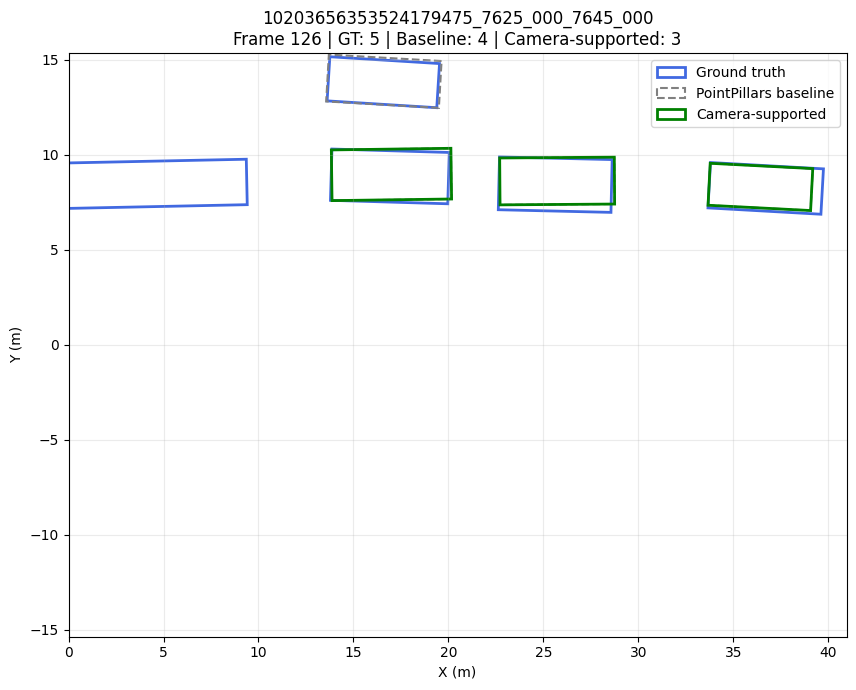

Saved: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/context_visualizations/10203656353524179475_7625_000_7645_000_bev_comparison.png


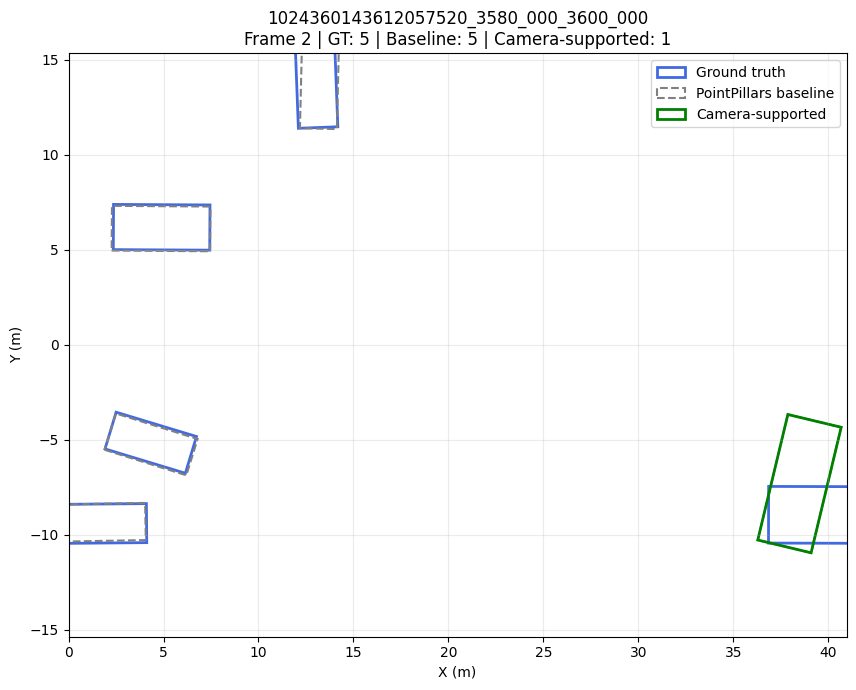

Saved: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/context_visualizations/1024360143612057520_3580_000_3600_000_bev_comparison.png


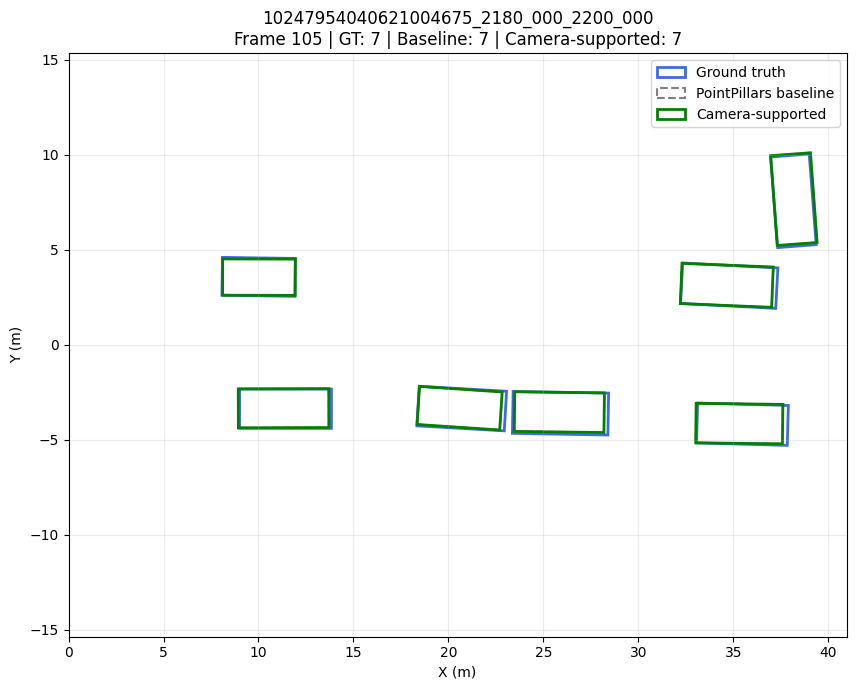

Saved: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/context_visualizations/10247954040621004675_2180_000_2200_000_bev_comparison.png


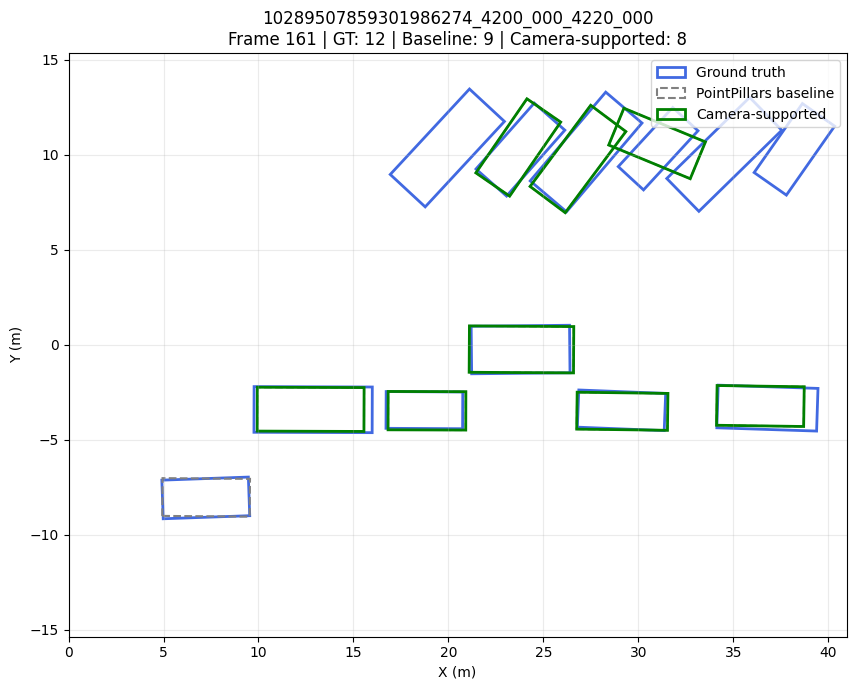

Saved: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/context_visualizations/10289507859301986274_4200_000_4220_000_bev_comparison.png


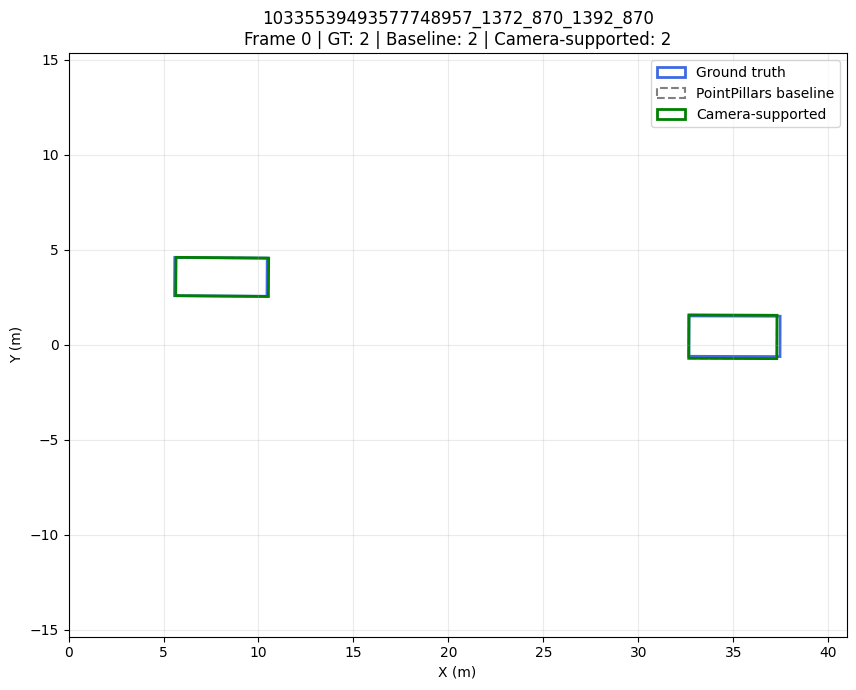

Saved: /content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/context_visualizations/10335539493577748957_1372_870_1392_870_bev_comparison.png


In [50]:
# Generates and saves BEV visualizations of predicted and ground-truth boxes across the validation contexts.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/3DPerception")
VALIDATION_ROOT = DRIVE_ROOT / "validation"
OUTPUT_ROOT = DRIVE_ROOT / "fusion_modular/outputs/validation"
PREDICTIONS_ROOT = OUTPUT_ROOT / "cleaned_predictions"
FIGURE_ROOT = OUTPUT_ROOT / "bev_evaluation" / "context_visualizations"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

CONTEXTS = [
    "10203656353524179475_7625_000_7645_000",
    "1024360143612057520_3580_000_3600_000",
    "10247954040621004675_2180_000_2200_000",
    "10289507859301986274_4200_000_4220_000",
    "10335539493577748957_1372_870_1392_870",
]

def get_col(df, *names):
    for name in names:
        if name in df.columns:
            return name
    raise KeyError(f"None of these columns found: {names}")

def box_corners(x, y, dx, dy, heading):
    local = np.array([
        [-dx/2, -dy/2], [dx/2, -dy/2],
        [dx/2, dy/2], [-dx/2, dy/2]
    ])
    c, s = np.cos(heading), np.sin(heading)
    rotation = np.array([[c, -s], [s, c]])
    return local @ rotation.T + np.array([x, y])

def draw_boxes(ax, rows, xcol, ycol, dxcol, dycol, hcol,
               color, label, linestyle="-", linewidth=1.5):
    first = True
    for _, r in rows.iterrows():
        corners = box_corners(
            float(r[xcol]), float(r[ycol]),
            float(r[dxcol]), float(r[dycol]), float(r[hcol])
        )
        ax.add_patch(Polygon(
            corners, closed=True, fill=False, edgecolor=color,
            linestyle=linestyle, linewidth=linewidth,
            label=label if first else None
        ))
        first = False

for context_id in CONTEXTS:
    pred_path = PREDICTIONS_ROOT / f"{context_id}_detections.csv"
    gt_path = VALIDATION_ROOT / "lidar_box" / f"{context_id}.parquet"
    pose_path = VALIDATION_ROOT / "vehicle_pose" / f"{context_id}.parquet"

    pred = pd.read_csv(pred_path)
    gt = pd.read_parquet(gt_path)
    pose = pd.read_parquet(pose_path)

    # Resolve the columns used by the saved files.
    pred_frame = get_col(pred, "frame_idx")
    pred_class = get_col(pred, "lidar_class")
    pred_x = get_col(pred, "x")
    pred_y = get_col(pred, "y")
    pred_dx = get_col(pred, "dx")
    pred_dy = get_col(pred, "dy")
    pred_heading = get_col(pred, "heading")
    matched_col = get_col(pred, "matched")

    timestamp_col = get_col(pose, "key.frame_timestamp_micros")
    gt_timestamp = get_col(gt, "key.frame_timestamp_micros")
    gt_type = get_col(gt, "[LiDARBoxComponent].type")
    gt_x = get_col(gt, "[LiDARBoxComponent].box.center.x")
    gt_y = get_col(gt, "[LiDARBoxComponent].box.center.y")
    gt_dx = get_col(gt, "[LiDARBoxComponent].box.size.x")
    gt_dy = get_col(gt, "[LiDARBoxComponent].box.size.y")
    gt_heading = get_col(gt, "[LiDARBoxComponent].box.heading")

    # Match frame_idx to timestamp using the same sorted unique pose timestamps.
    timestamps = sorted(pose[timestamp_col].dropna().unique())
    frame_to_timestamp = dict(enumerate(timestamps))

    pred = pred[
        pred[pred_class].astype(str).str.lower().eq("vehicle")
        & pred[pred_x].ge(0) & pred[pred_x].lt(40.96)
        & pred[pred_y].ge(-15.36) & pred[pred_y].lt(15.36)
    ].copy()

    pred["_supported"] = (
        pred[matched_col].astype(str).str.strip().str.lower()
        .isin({"true", "1", "yes"})
    )

    # Choose a representative frame with the most supported predictions.
    supported_counts = pred[pred["_supported"]].groupby(pred_frame).size()
    if supported_counts.empty:
        frame_idx = int(pred[pred_frame].iloc[0]) if not pred.empty else 0
    else:
        frame_idx = int(supported_counts.idxmax())

    timestamp = frame_to_timestamp.get(frame_idx)
    if timestamp is None:
        print(f"Skipping {context_id}: frame {frame_idx} has no pose timestamp.")
        continue

    baseline_frame = pred[pred[pred_frame] == frame_idx]
    supported_frame = baseline_frame[baseline_frame["_supported"]]
    gt_frame = gt[
        (gt[gt_timestamp] == timestamp) & (gt[gt_type] == 1)
    ].copy()

    # Apply the same evaluation ROI to ground truth.
    gt_frame = gt_frame[
        gt_frame[gt_x].ge(0) & gt_frame[gt_x].lt(40.96)
        & gt_frame[gt_y].ge(-15.36) & gt_frame[gt_y].lt(15.36)
    ]

    fig, ax = plt.subplots(figsize=(11, 7))

    draw_boxes(
        ax, gt_frame, gt_x, gt_y, gt_dx, gt_dy, gt_heading,
        "royalblue", "Ground truth", linewidth=2
    )
    draw_boxes(
        ax, baseline_frame, pred_x, pred_y, pred_dx, pred_dy, pred_heading,
        "grey", "PointPillars baseline", linestyle="--"
    )
    draw_boxes(
        ax, supported_frame, pred_x, pred_y, pred_dx, pred_dy, pred_heading,
        "green", "Camera-supported", linewidth=2
    )

    ax.set_xlim(0, 40.96)
    ax.set_ylim(-15.36, 15.36)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_title(
        f"{context_id}\nFrame {frame_idx} | "
        f"GT: {len(gt_frame)} | Baseline: {len(baseline_frame)} | "
        f"Camera-supported: {len(supported_frame)}"
    )
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper right")
    fig.tight_layout()

    output_path = FIGURE_ROOT / f"{context_id}_bev_comparison.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")


/content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/10247954040621004675_2180_000_2200_000/frame_105.jpg


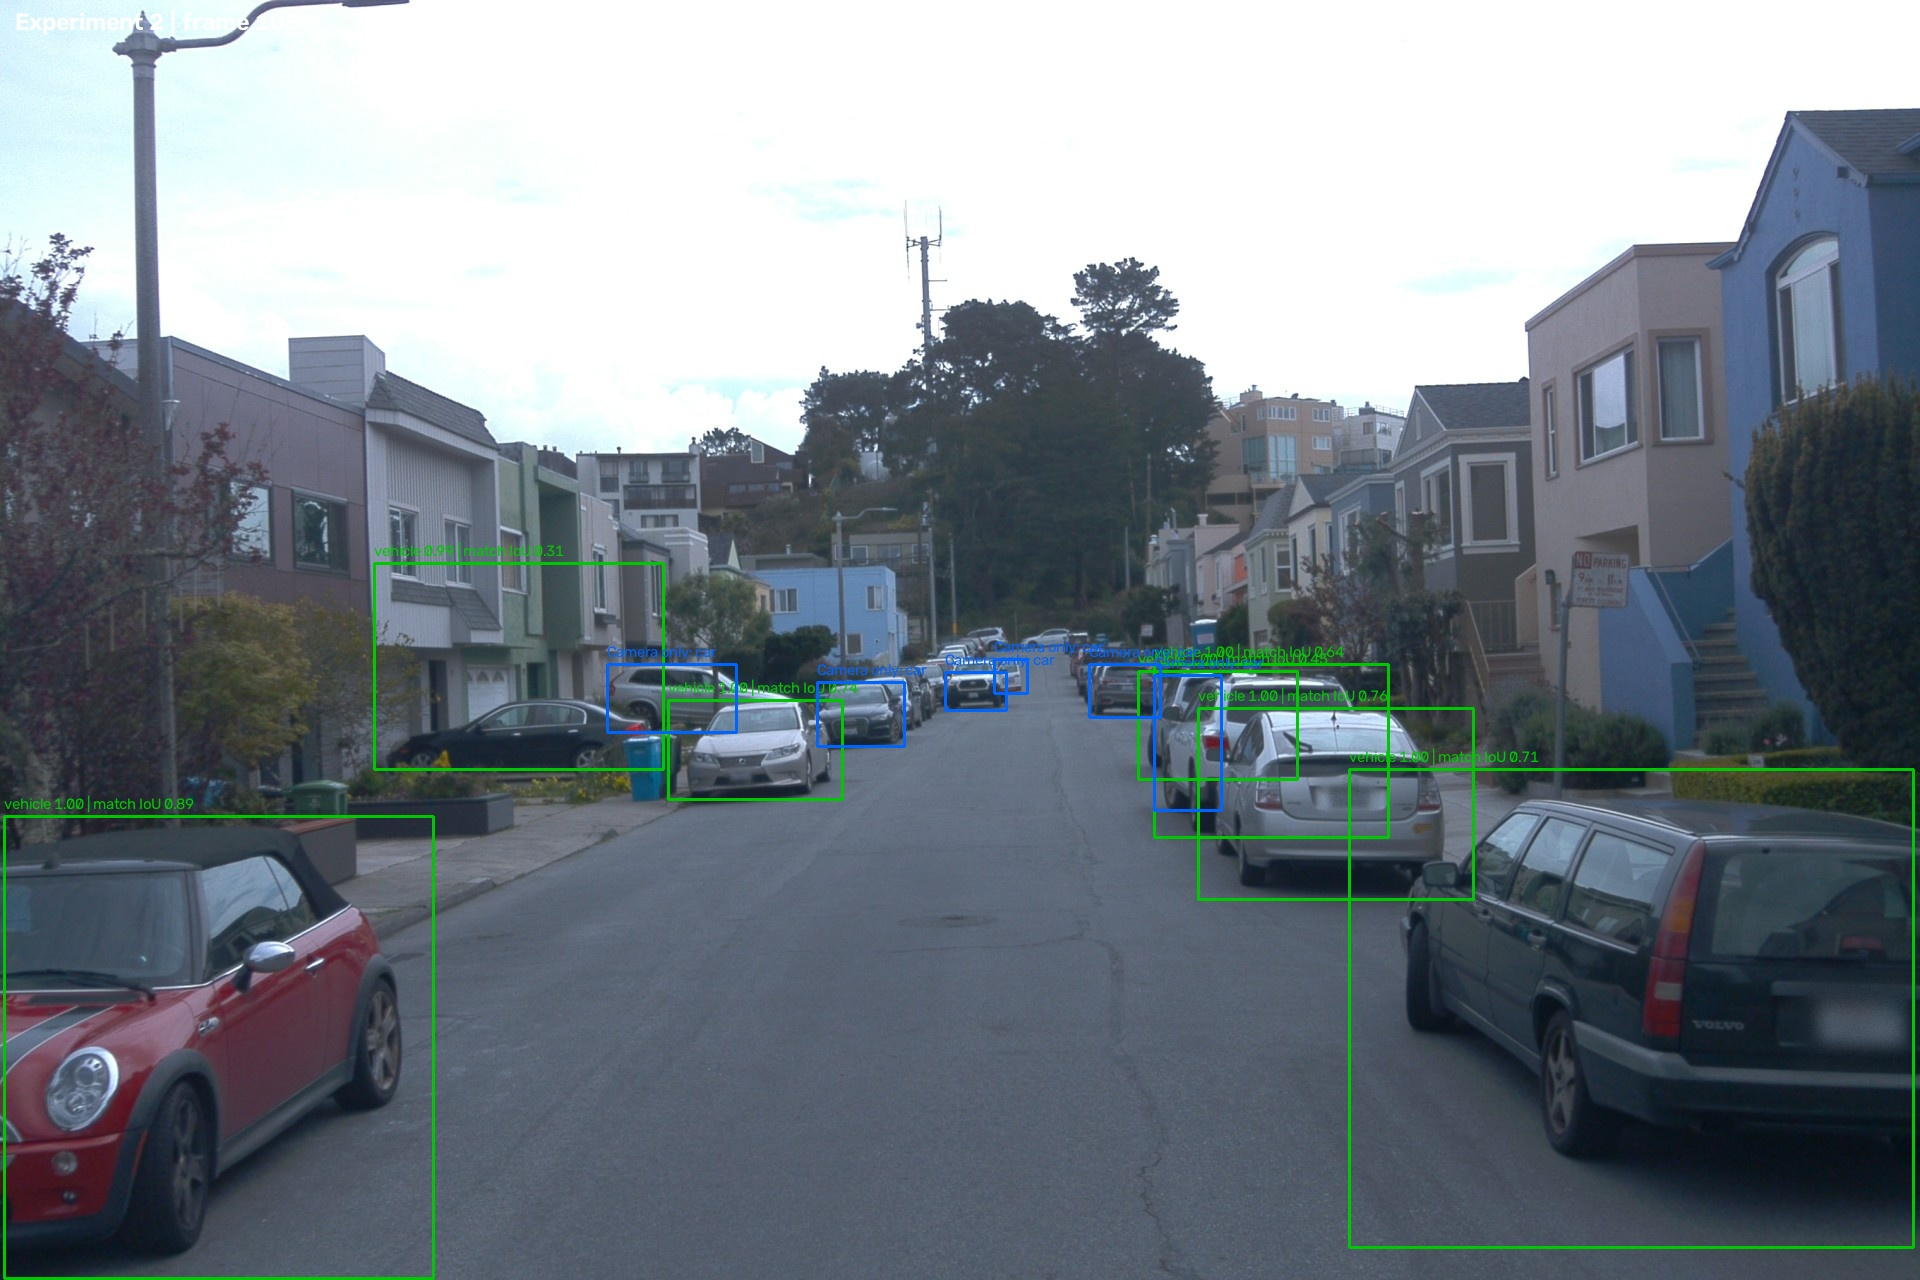

In [52]:
# Displays one selected camera-frame visualization from a specific context and frame.
from pathlib import Path
from IPython.display import display, Image

ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/3DPerception/"
    "fusion_modular/outputs/validation"
)

context_id = "10247954040621004675_2180_000_2200_000"
frame_idx = 105

image_path = ROOT / context_id / f"frame_{frame_idx:03d}.jpg"
print(image_path)
display(Image(filename=str(image_path)))


Context: 10203656353524179475_7625_000_7645_000 | Frame: 126


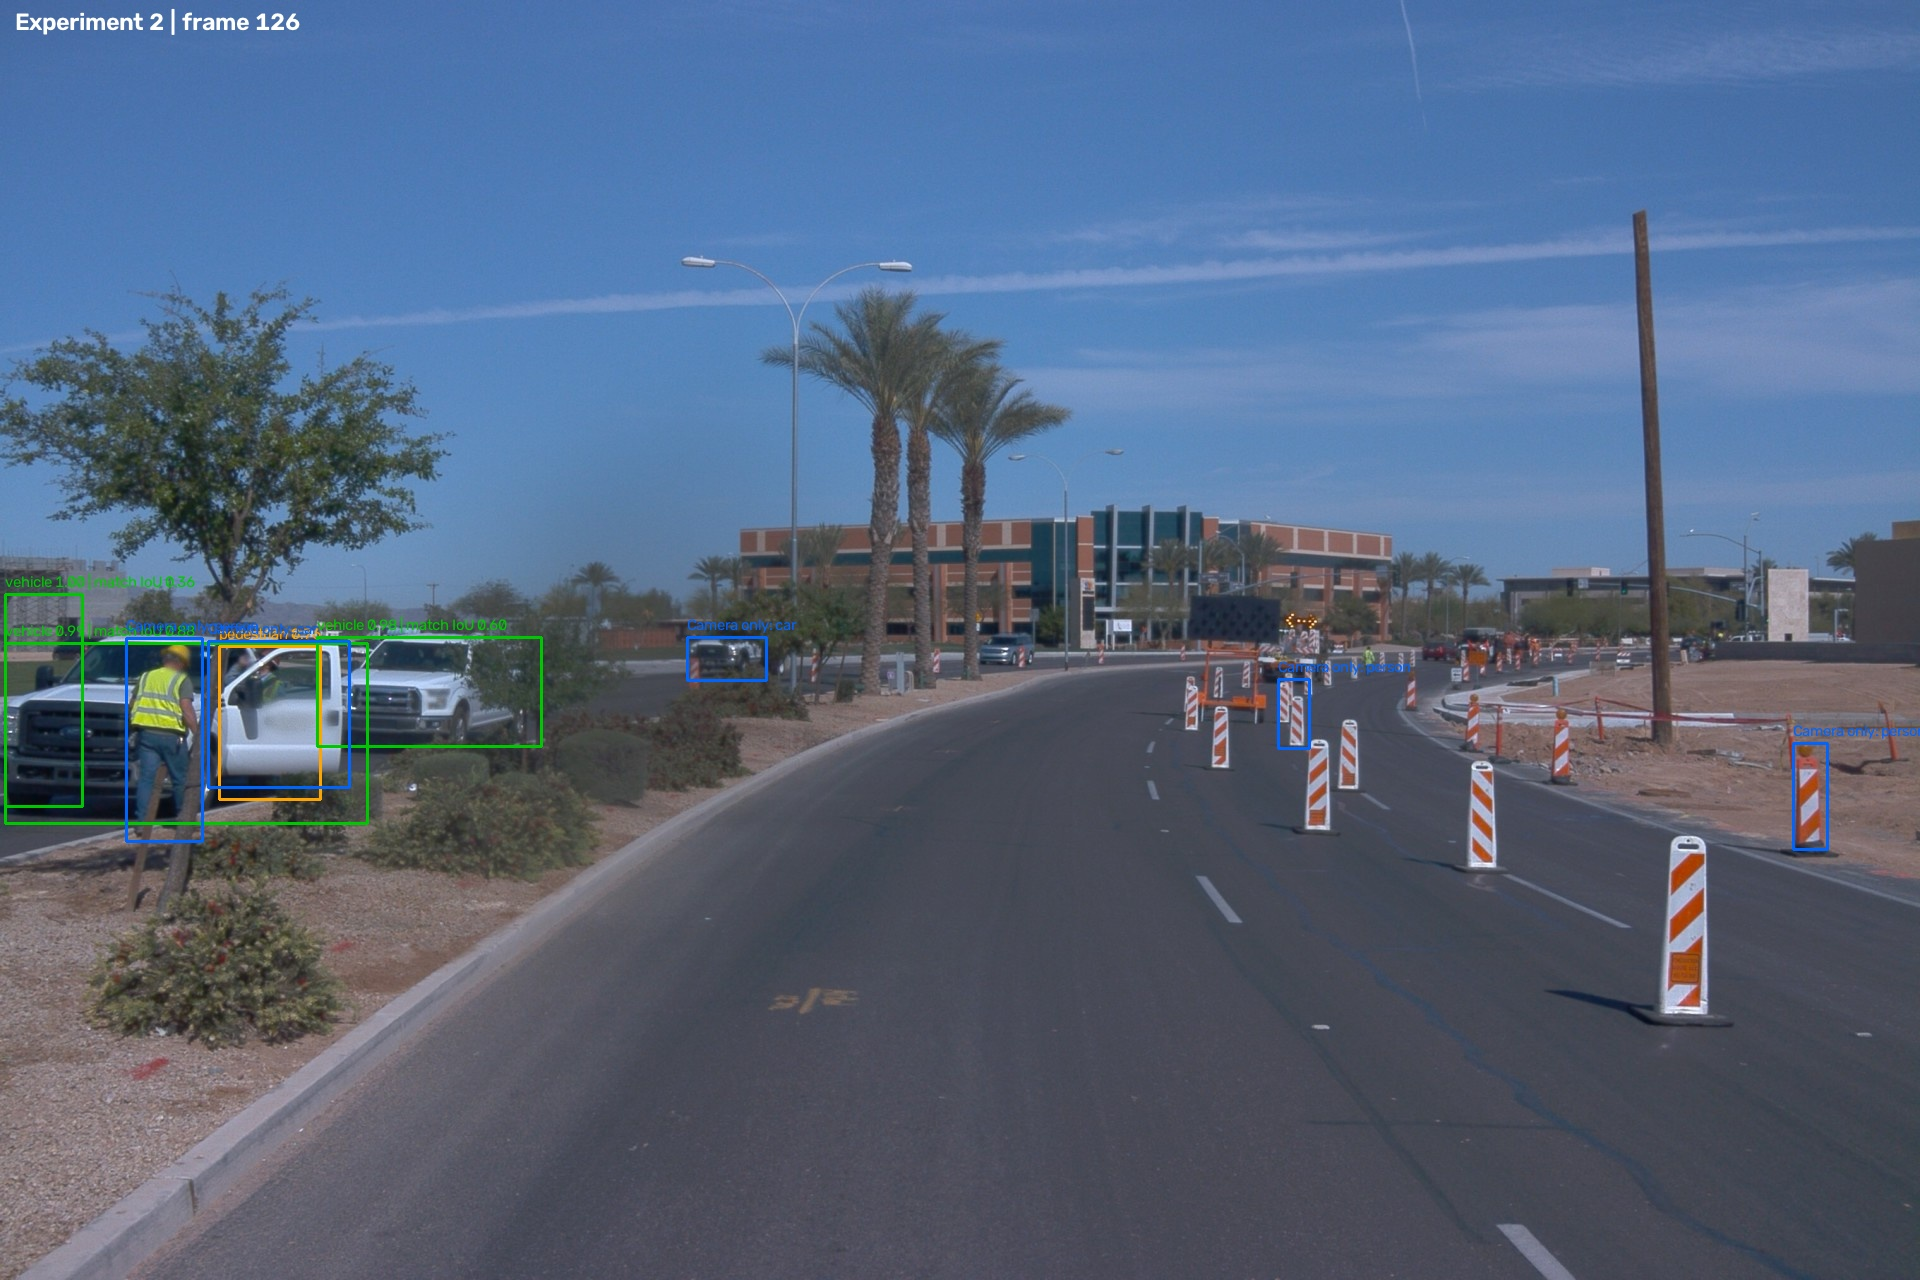


Context: 1024360143612057520_3580_000_3600_000 | Frame: 2


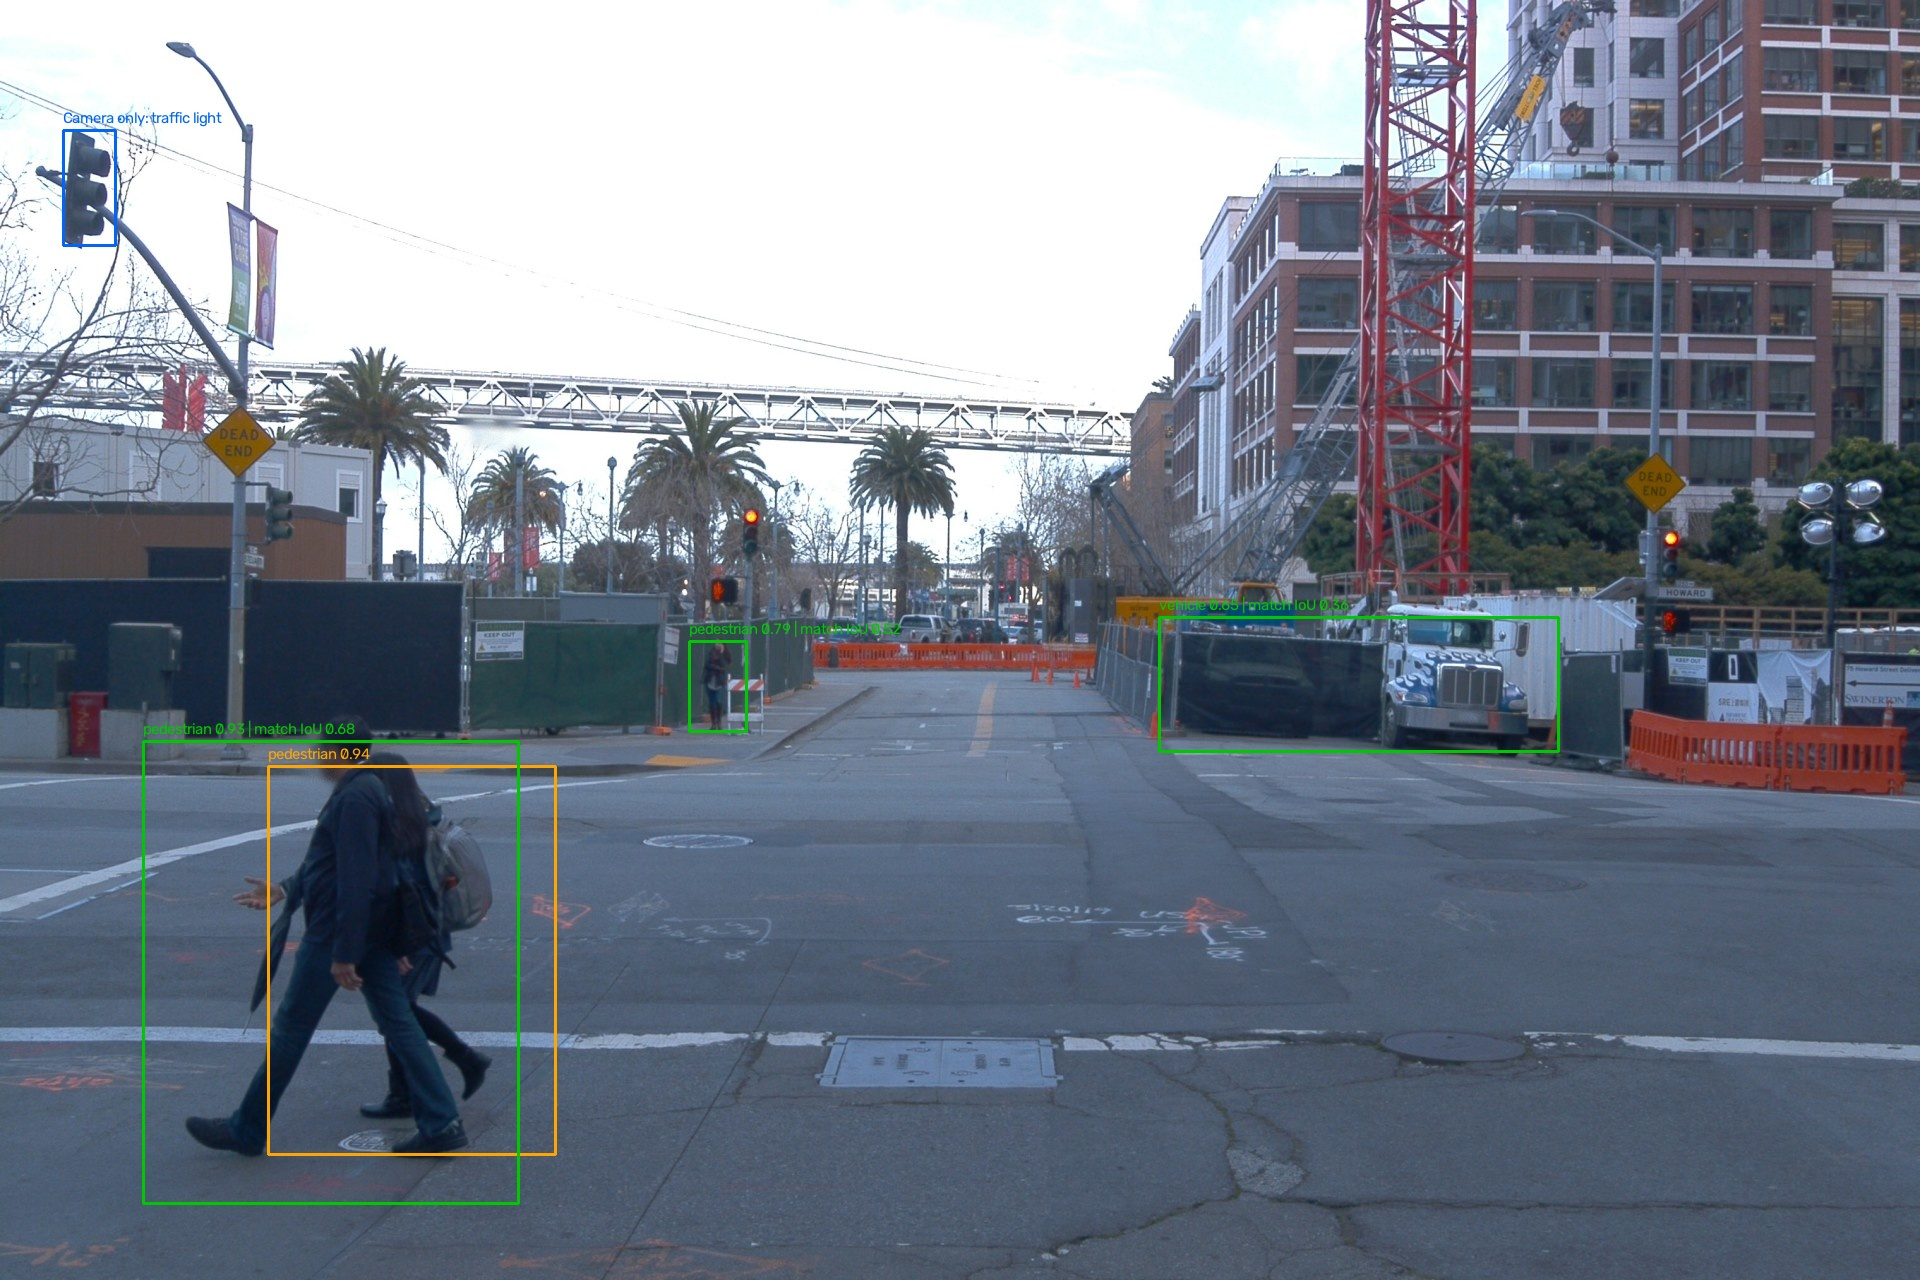


Context: 10247954040621004675_2180_000_2200_000 | Frame: 105


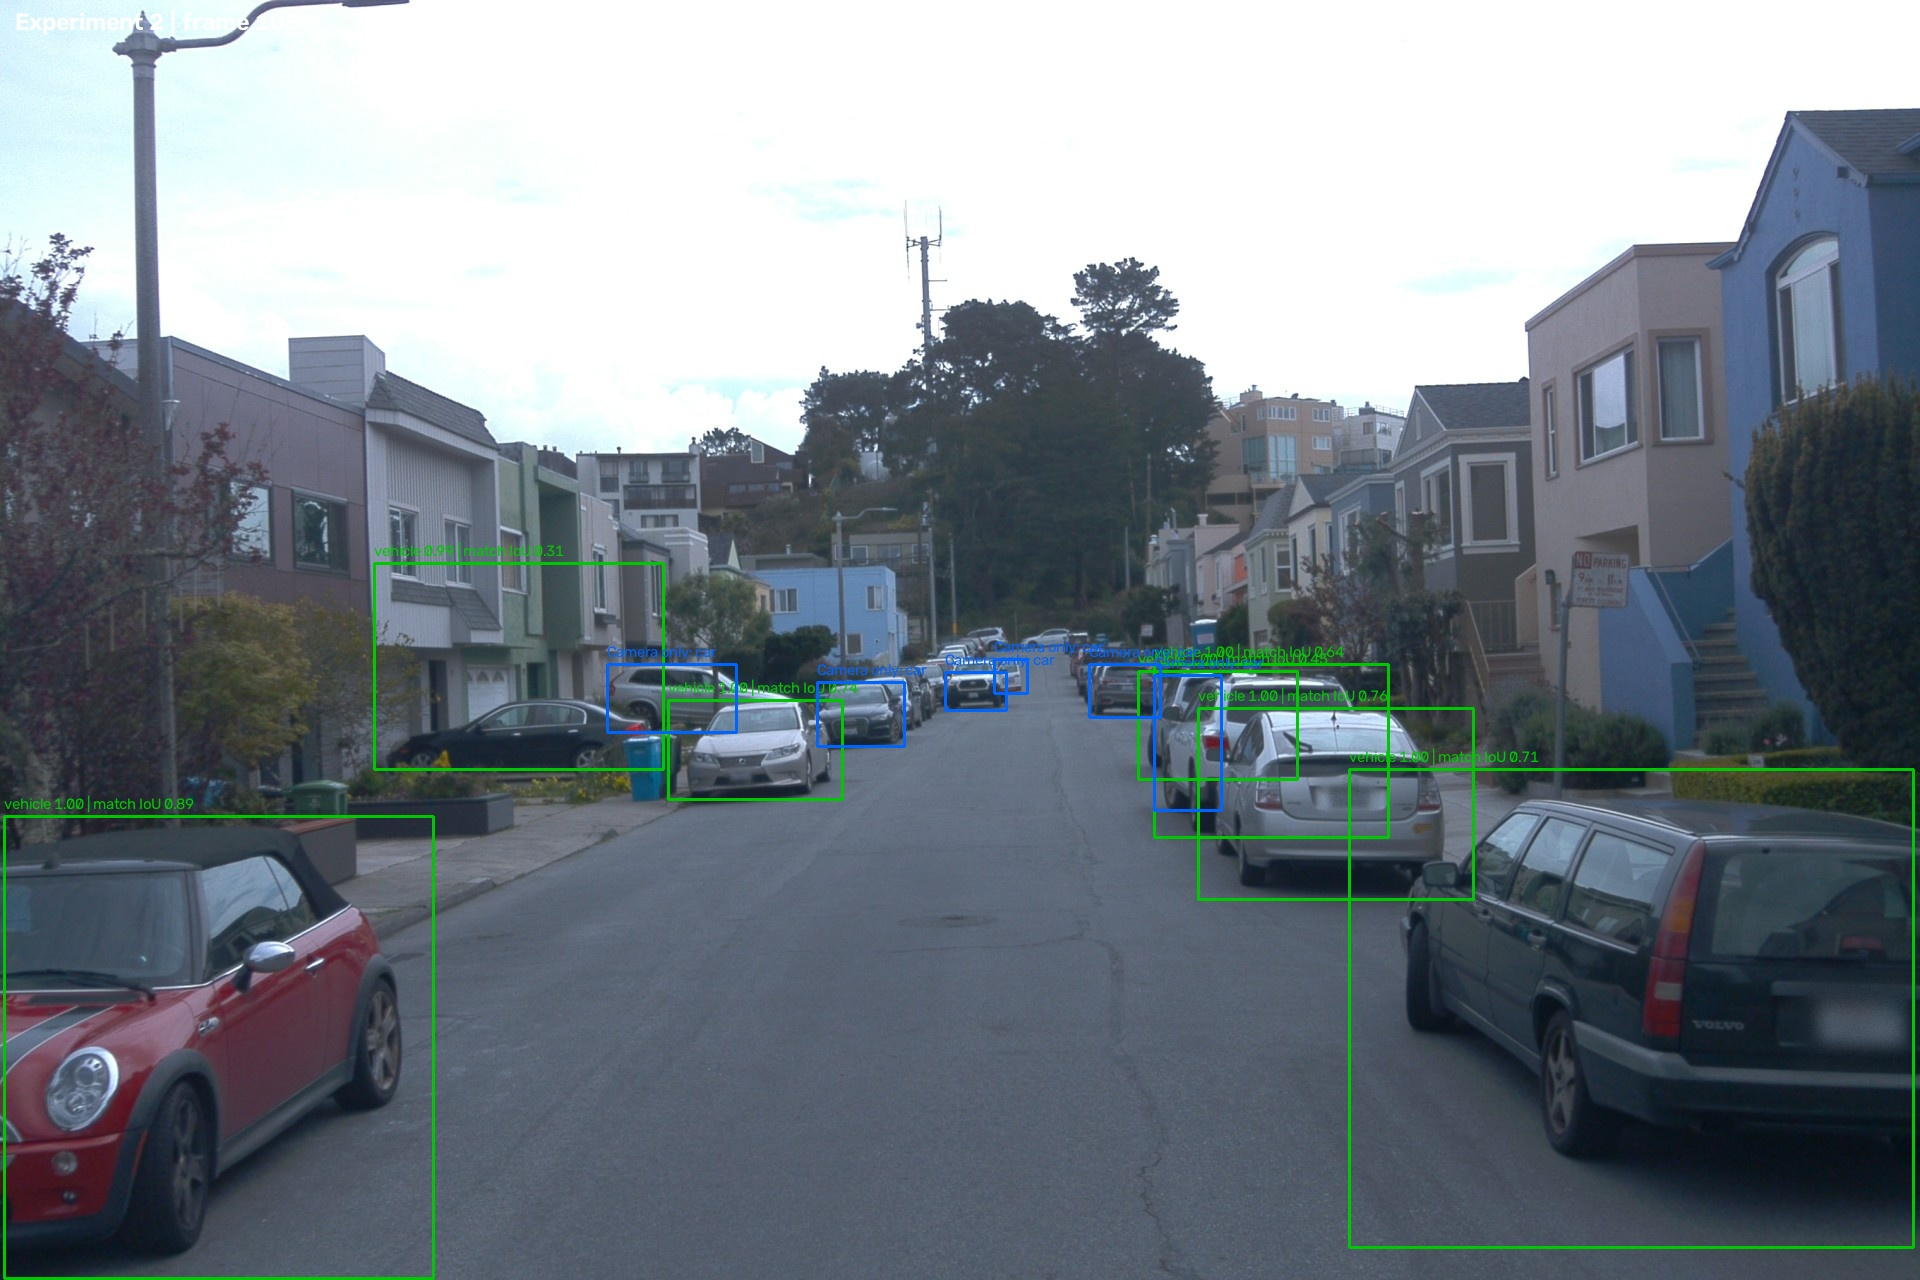


Context: 10289507859301986274_4200_000_4220_000 | Frame: 161


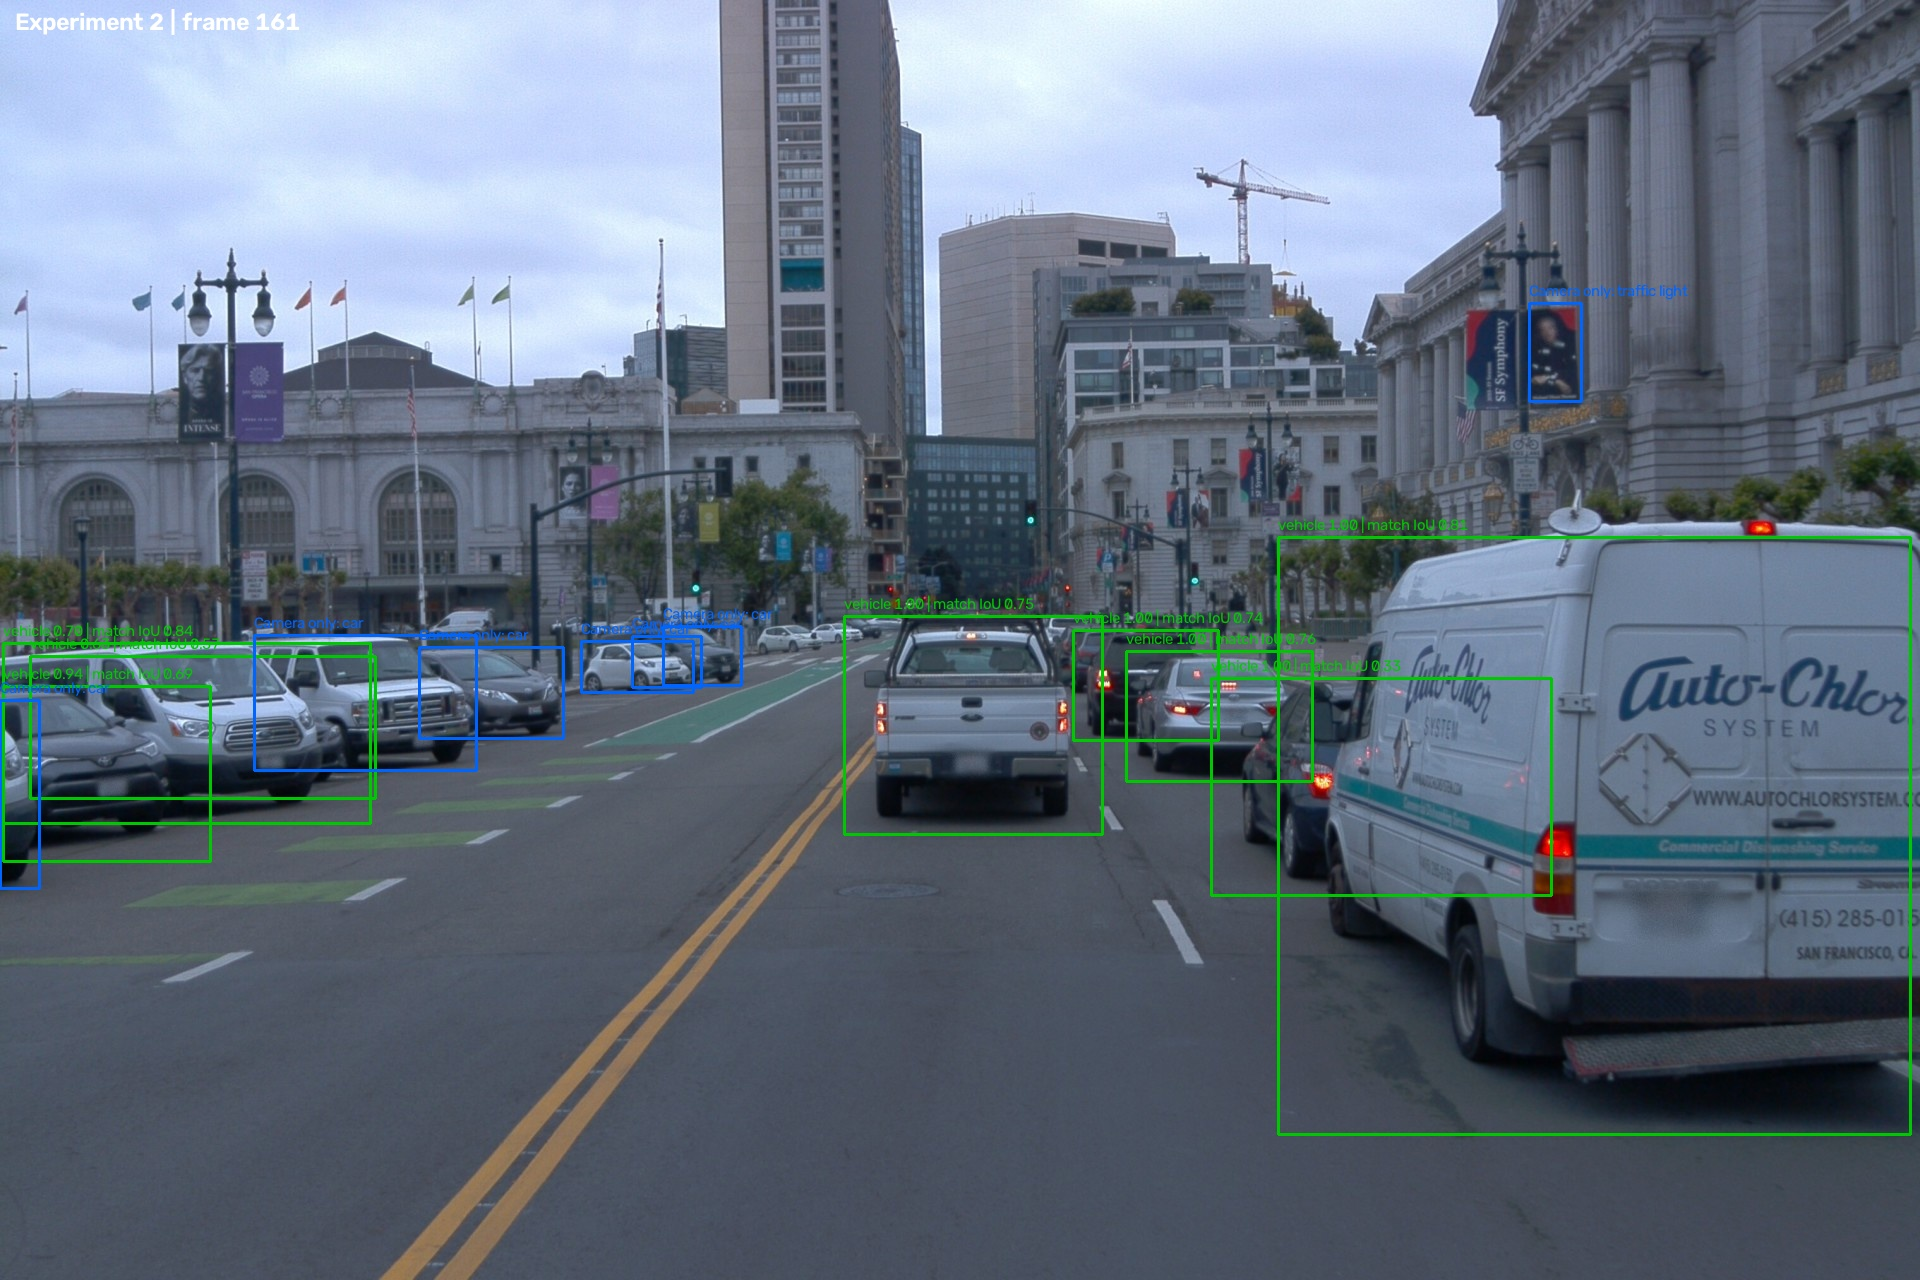


Context: 10335539493577748957_1372_870_1392_870 | Frame: 0


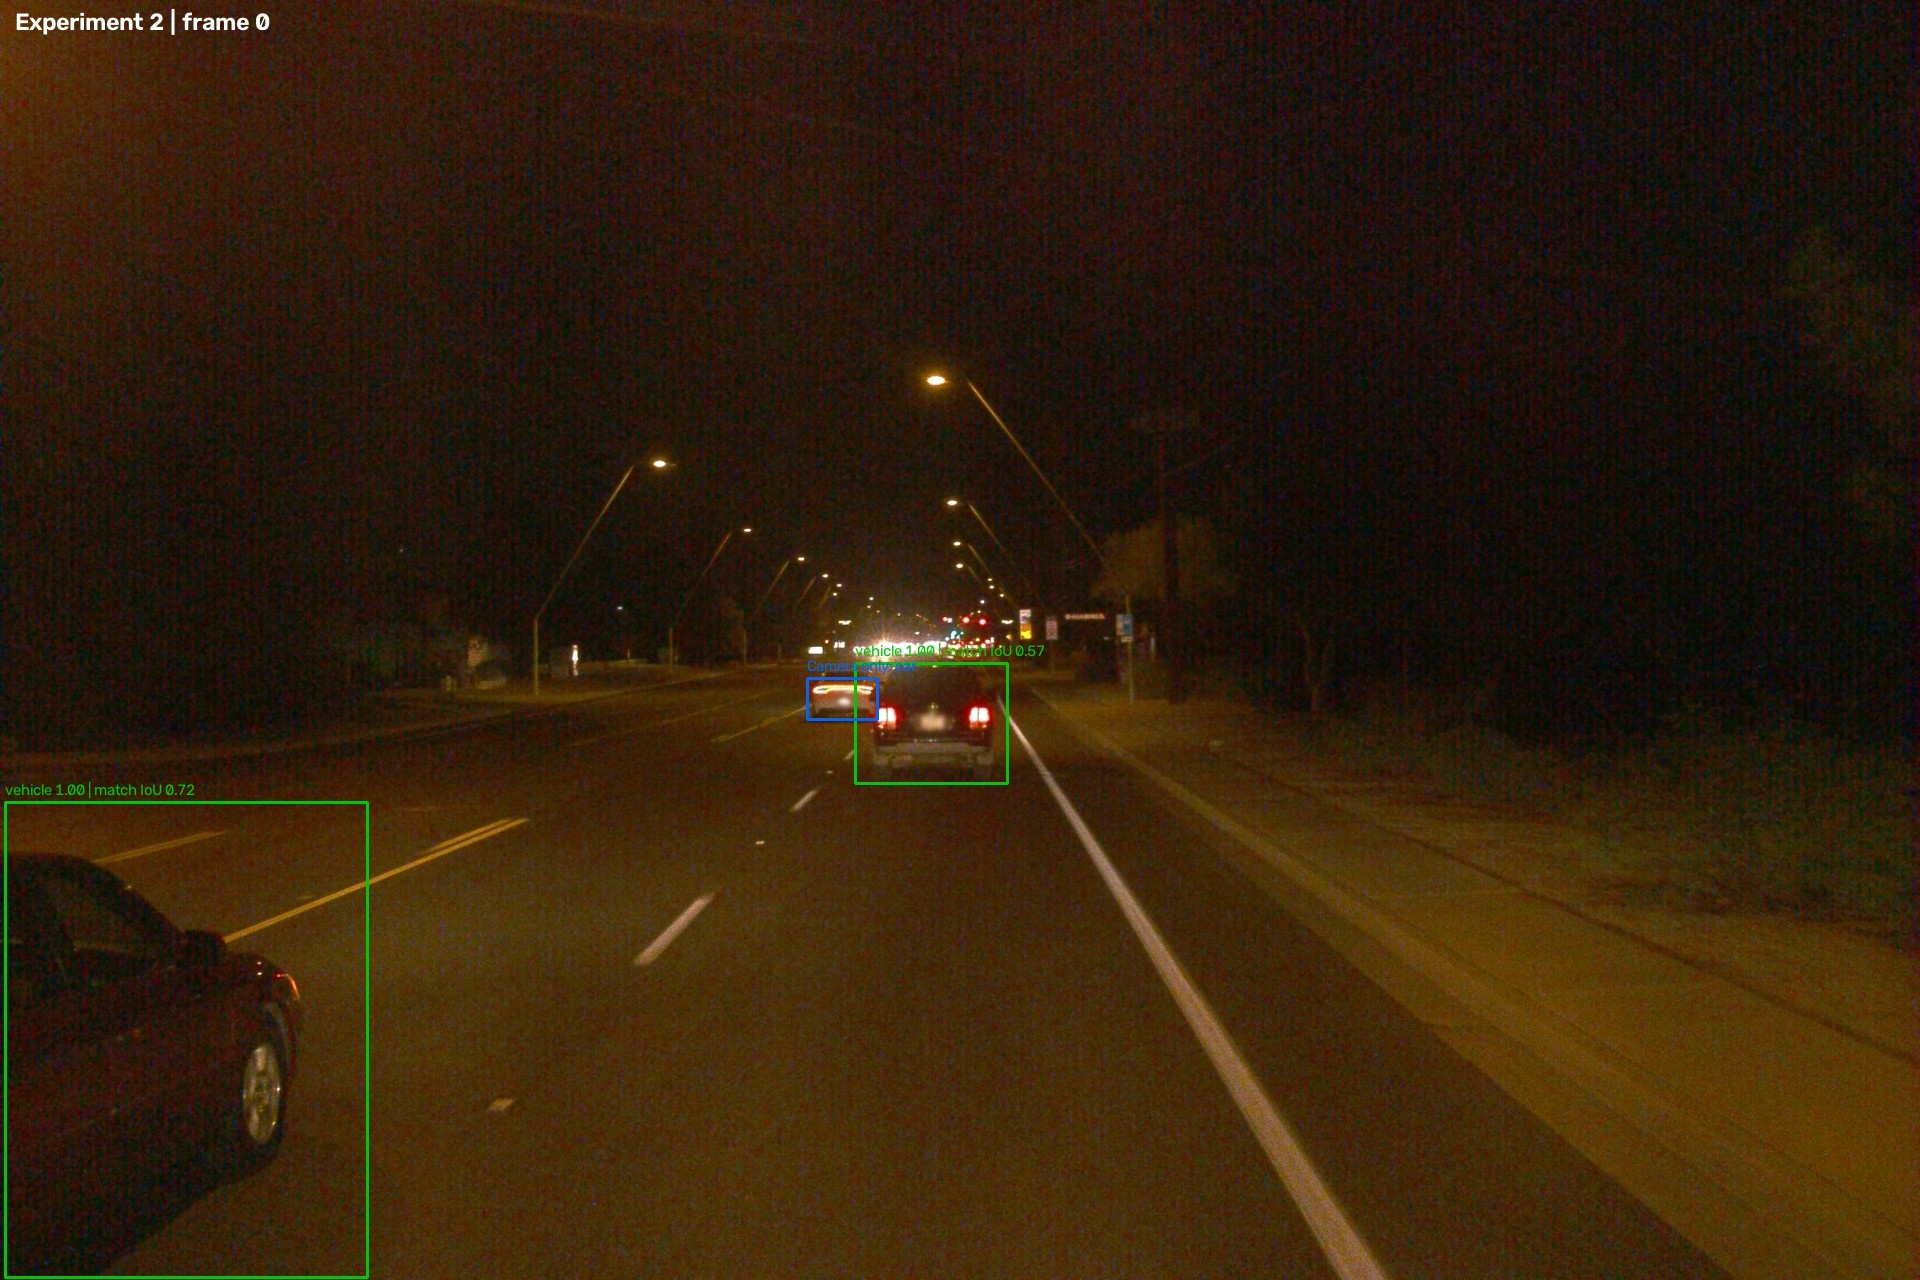


Selected visualizations saved to:
/content/drive/MyDrive/Colab Notebooks/3DPerception/fusion_modular/outputs/validation/bev_evaluation/selected_camera_lidar_frames


In [53]:
# Copies and displays selected camera–LiDAR visualizations for all five contexts.
from pathlib import Path
import shutil
from IPython.display import display, Image

DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/3DPerception")
OUTPUT_ROOT = DRIVE_ROOT / "fusion_modular/outputs/validation"
FIGURE_ROOT = OUTPUT_ROOT / "bev_evaluation" / "selected_camera_lidar_frames"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

selected_frames = {
    "10203656353524179475_7625_000_7645_000": 126,
    "1024360143612057520_3580_000_3600_000": 2,
    "10247954040621004675_2180_000_2200_000": 105,
    "10289507859301986274_4200_000_4220_000": 161,
    "10335539493577748957_1372_870_1392_870": 0,
}

for context_id, frame_idx in selected_frames.items():
    source = OUTPUT_ROOT / context_id / f"frame_{frame_idx:03d}.jpg"

    if not source.exists():
        print(f"Missing image: {source}")
        continue

    destination = FIGURE_ROOT / f"{context_id}_frame_{frame_idx:03d}.jpg"
    shutil.copy2(source, destination)

    print(f"\nContext: {context_id} | Frame: {frame_idx}")
    display(Image(filename=str(destination)))

print(f"\nSelected visualizations saved to:\n{FIGURE_ROOT}")

- Green boxes show LiDAR vehicle detections projected into the camera image, with the match IoU indicated in the labels.
- Blue boxes show camera-only detections that were not associated with a compatible LiDAR detection.
- Some boxes overlap or differ in size, which helps illustrate why camera–LiDAR association is not always straightforward.
- The traffic-light detection illustrates that the camera can detect objects outside the vehicle classes evaluated by our LiDAR filtering strategy.